Investigating Data Efficiency and Generalisation in Hybrid Quantum-Classical Vision Transformers

1. Research Overview

This project investigates how the availability of training data affects the classification performance and generalisation of classical and hybrid quantum-classical vision models.

The study will evaluate models using different proportions of the training dataset while maintaining consistent evaluation procedures.

Research Objectives

1. Establish a classical image-classification baseline.
2. Investigate performance at 10%, 25%, 50%, and 100% training-data availability.
3. Evaluate the variability of results across random seeds.
4. Compare predictive performance and computational cost.
5. Determine whether experimental results support any measurable benefit from the hybrid approach.

Experimental Principles

- Use consistent training, validation, and test partitions.
- Control random seeds and document model configurations.
- Use identical evaluation metrics for comparable models.
- Report repeated-run results and variability.
- Avoid assuming quantum advantage before examining experimental evidence.

Initial Dataset

CIFAR-10 will serve as the initial benchmark. It contains colour images from 10 object categories.

Expected Outputs

- Dataset exploration and visualisation.
- Training-data subset definitions.
- Classical baseline results.
- Hybrid model results.
- Comparative plots and statistical summaries.
- Discussion of limitations and conclusions.


2. Environment and Reproducibility

This section imports the libraries required for numerical computation, data analysis, visualisation, and deep learning.

A fixed initial random seed is used to improve reproducibility. However, identical results are not guaranteed across all hardware configurations or nondeterministic operations.

The computation device is selected automatically based on CUDA availability.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cpu
NumPy: 2.5.4
Pandas: 3.1.0


3. Dataset Acquisition and Preprocessing

CIFAR-10 is a benchmark dataset containing 60,000 colour images of size 32 × 32 pixels, distributed across 10 classes.

The standard split consists of 50,000 training images and 10,000 test images.

The training set will be used to fit the models. The test set will be reserved for final evaluation and will not be used to select model configurations.

The images will be converted into tensors and normalised using commonly used CIFAR-10 channel statistics.

Reproducibility note: The training data will subsequently be divided into training and validation subsets. Validation data will support model selection, while the test set will remain untouched until final evaluation.

In [2]:
from torchvision import datasets, transforms
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform
)

CLASS_NAMES = train_dataset.classes

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Number of classes:", len(CLASS_NAMES))
print("Class names:", CLASS_NAMES)

Training images: 50000
Test images: 10000
Number of classes: 10
Class names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


4. Exploratory Data Visualisation

Visual inspection provides an initial understanding of the image resolution, object categories, and visual diversity present in the dataset.

Ten training images will be displayed with their corresponding class labels.

The normalisation transformation will be reversed for display purposes only. The original dataset tensors will remain unchanged.

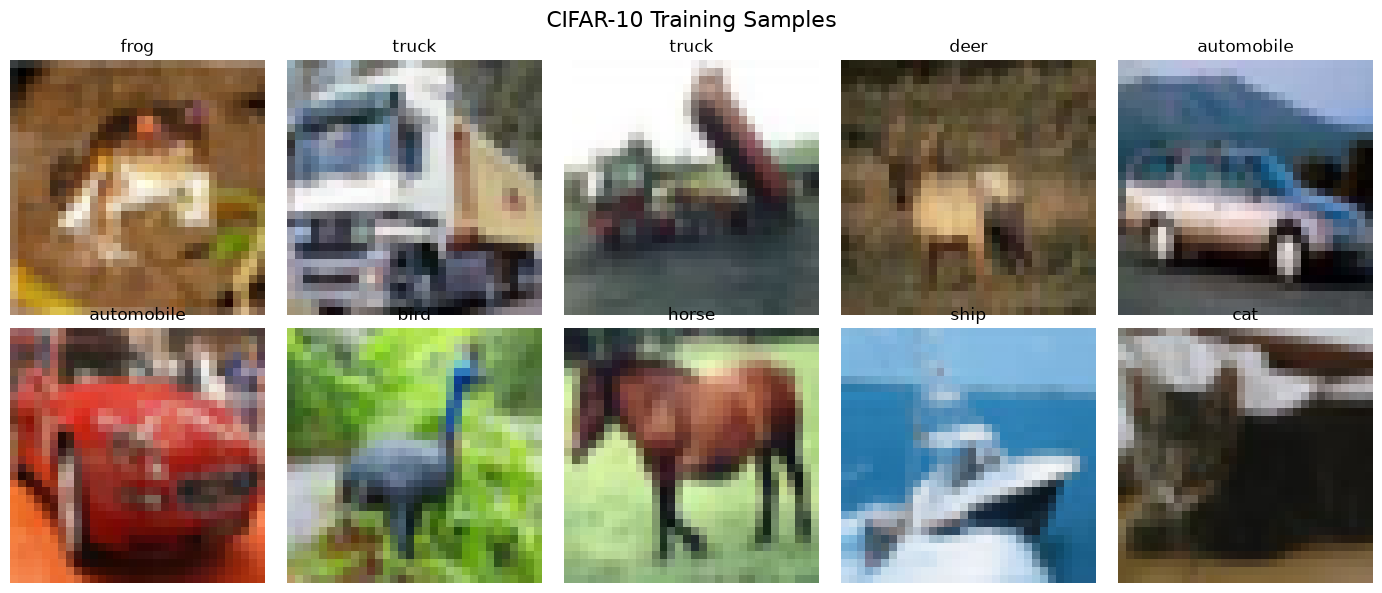

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    # Reverse normalisation for visualisation
    image = image * std + mean
    image = image.clamp(0, 1)
    image = image.permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")

plt.suptitle("CIFAR-10 Training Samples", fontsize=16)
plt.tight_layout()
plt.show()

5. Controlled Training-Data Subsets

Objective

Investigate how training-data availability affects image-classification performance.

Four training-data fractions will be evaluated:

- 10%: 5,000 images
- 25%: 12,500 images
- 50%: 25,000 images
- 100%: 50,000 images

These fractions refer to the original CIFAR-10 training set. The test set remains separate and is not used to construct the training subsets.

Methodology

A fixed random seed will be used to select reproducible subsets. The subsets will be nested: the 10% subset will be contained in the 25% subset, which will be contained in the 50% subset, and so on.

This approach makes comparisons across data fractions easier to interpret because larger subsets retain the examples included in smaller subsets.

Important: These are training subsets, not final train/validation splits. We will establish a consistent validation protocol before training models. Any validation examples must be excluded from the data available for model fitting.


In [4]:
from torch.utils.data import Subset

DATA_FRACTIONS = [0.10, 0.25, 0.50, 1.00]

subset_rng = np.random.default_rng(SEED)

# Generate one reproducible ordering of training indices.
permuted_indices = subset_rng.permutation(len(train_dataset))

train_subsets = {}

for fraction in DATA_FRACTIONS:
    subset_size = int(len(train_dataset) * fraction)
    indices = permuted_indices[:subset_size].tolist()

    train_subsets[fraction] = Subset(train_dataset, indices)

    print(
        f"{fraction:>5.0%} of training data: "
        f"{len(train_subsets[fraction]):,} images"
    )

  10% of training data: 5,000 images
  25% of training data: 12,500 images
  50% of training data: 25,000 images
 100% of training data: 50,000 images


6. Verify Subset Construction

We verify that the subsets contain the intended number of images and that the nested-subset property holds.

This check helps prevent accidental inconsistencies in the data-efficiency experiment.

In [5]:
assert len(train_subsets[0.10]) == 5_000
assert len(train_subsets[0.25]) == 12_500
assert len(train_subsets[0.50]) == 25_000
assert len(train_subsets[1.00]) == 50_000

indices_by_fraction = {
    fraction: set(subset.indices)
    for fraction, subset in train_subsets.items()
}

assert indices_by_fraction[0.10].issubset(indices_by_fraction[0.25])
assert indices_by_fraction[0.25].issubset(indices_by_fraction[0.50])
assert indices_by_fraction[0.50].issubset(indices_by_fraction[1.00])

print("All subset-size and nesting checks passed.")

All subset-size and nesting checks passed.


7. Training and Validation Protocol

Objective

Create mutually exclusive training and validation partitions.

The original CIFAR-10 training set contains 50,000 images. We will reserve 5,000 images for validation and use the remaining 45,000 as the training pool.

The four data fractions will now be calculated from this 45,000-image pool. The resulting subset sizes will therefore differ from those calculated using the entire original training set.

The 10,000-image CIFAR-10 test set remains untouched until final evaluation.

Data Leakage Prevention

- Validation images will not be used for gradient updates.
- Test images will not be used for hyperparameter selection.
- The same validation and test partitions will be used when comparing models.
- Subset selection will be reproducible.

In [6]:
from torch.utils.data import random_split

VALIDATION_SIZE = 5_000
TRAIN_POOL_SIZE = len(train_dataset) - VALIDATION_SIZE

split_generator = torch.Generator().manual_seed(SEED)

train_pool, validation_dataset = random_split(
    train_dataset,
    [TRAIN_POOL_SIZE, VALIDATION_SIZE],
    generator=split_generator
)

print("Training pool:", len(train_pool))
print("Validation set:", len(validation_dataset))
print("Test set:", len(test_dataset))

Training pool: 45000
Validation set: 5000
Test set: 10000


In [7]:
pool_indices = np.random.default_rng(SEED).permutation(
    len(train_pool)
)

train_subsets = {}

for fraction in DATA_FRACTIONS:
    subset_size = int(len(train_pool) * fraction)

    indices = pool_indices[:subset_size].tolist()

    train_subsets[fraction] = Subset(
        train_pool,
        indices
    )

    print(
        f"{fraction:>5.0%}: "
        f"{len(train_subsets[fraction]):,} training images"
    )

print("\nValidation images:", len(validation_dataset))
print("Test images:", len(test_dataset))

  10%: 4,500 training images
  25%: 11,250 training images
  50%: 22,500 training images
 100%: 45,000 training images

Validation images: 5000
Test images: 10000


8. Classical Convolutional Neural Network Baseline

Objective

Establish a classical image-classification baseline for CIFAR-10.

A convolutional neural network (CNN) is used to learn spatial features from images and predict one of the ten CIFAR-10 classes.

Architecture

The baseline contains:

- Two convolutional layers with ReLU activations.
- Max-pooling layers for spatial downsampling.
- A fully connected classification head.
- Ten output logits, one for each class.

Experimental Role

This model provides a reference for later comparison with the hybrid quantum-classical model. The baseline uses standard classical computation and does not contain a quantum circuit.

We will first train on 10% of the training pool. This initial run is a pipeline check, not a final scientific result.

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ClassicalCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = ClassicalCNN().to(DEVICE)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

ClassicalCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 545098


9. Mini-batch Data Loading

Training data is processed in mini-batches to manage memory usage and perform stochastic gradient descent.

The initial experiment uses:

- Training fraction: 10%
- Batch size: 128
- Shuffling: enabled for training
- Shuffling: disabled for validation

The validation set remains separate from the training subset.

In [9]:
from torch.utils.data import DataLoader

BATCH_SIZE = 128

train_loader = DataLoader(
    train_subsets[0.10],
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Device:", DEVICE)

Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])
Device: cpu


10. Training and Evaluation Procedure

The model will be trained using cross-entropy loss and the Adam optimiser.

After each epoch, validation loss and accuracy will be calculated. Validation data will not be used for gradient updates.

We will record:

- Training loss
- Validation loss
- Training accuracy
- Validation accuracy
- Epoch duration

For this initial pipeline check, we will run three epochs. This is not necessarily sufficient for optimal model performance.

In [10]:
import time


def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples,
    }


def train_model(model, train_loader, validation_loader, epochs=3, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = []

    for epoch in range(1, epochs + 1):
        start_time = time.perf_counter()

        model.train()

        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

        train_loss = total_loss / total_samples
        train_accuracy = total_correct / total_samples

        val_metrics = evaluate(
            model,
            validation_loader,
            criterion
        )

        epoch_seconds = time.perf_counter() - start_time

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": val_metrics["loss"],
            "validation_accuracy": val_metrics["accuracy"],
            "epoch_seconds": epoch_seconds,
        }

        history.append(row)

        print(
            f"Epoch {epoch}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train acc: {train_accuracy:.2%} | "
            f"Val loss: {val_metrics['loss']:.4f} | "
            f"Val acc: {val_metrics['accuracy']:.2%} | "
            f"Time: {epoch_seconds:.1f}s"
        )

    return pd.DataFrame(history)

11. Initial Baseline Experiment: 10% Training Data

We now train the classical CNN using the 10% training subset.

This experiment checks that:

1. The model's forward and backward passes work.
2. Parameters update during training.
3. Training and validation metrics are computed correctly.
4. Results can be stored for subsequent analysis.

The model has not yet been tuned, and its results should not be interpreted as a definitive benchmark.

In [11]:
# Reset the seed before initialising the baseline model.
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

baseline_model = ClassicalCNN().to(DEVICE)

baseline_history = train_model(
    model=baseline_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=3,
    lr=1e-3
)

baseline_history

Epoch 1/3 | Train loss: 2.0910 | Train acc: 23.71% | Val loss: 1.8277 | Val acc: 36.84% | Time: 10.6s
Epoch 2/3 | Train loss: 1.7518 | Train acc: 37.64% | Val loss: 1.5759 | Val acc: 44.32% | Time: 8.3s
Epoch 3/3 | Train loss: 1.5536 | Train acc: 44.20% | Val loss: 1.4749 | Val acc: 48.28% | Time: 7.8s


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds
0,1,2.091011,0.237111,1.827678,0.3684,10.641100
1,2,1.751817,0.376444,1.575895,0.4432,8.330071
2,3,1.553624,0.442000,1.474924,0.4828,7.758380


12. Baseline Learning Curves

Learning curves show how training and validation performance change over successive epochs.

Training loss should generally decrease as the model learns. Validation performance helps assess whether improvements on the training data translate to unseen examples.

A widening gap between training and validation performance can indicate overfitting, although conclusions should be based on the full training history rather than a single epoch.

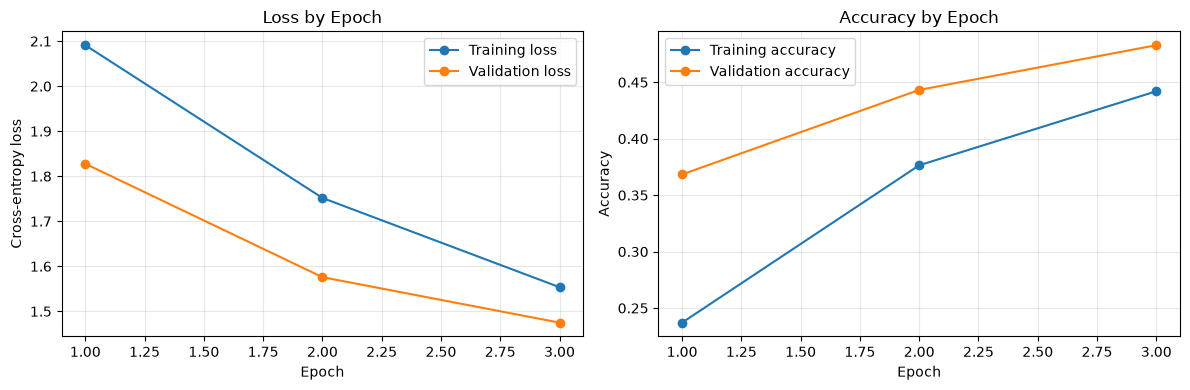

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    baseline_history["epoch"],
    baseline_history["train_loss"],
    marker="o",
    label="Training loss"
)

axes[0].plot(
    baseline_history["epoch"],
    baseline_history["validation_loss"],
    marker="o",
    label="Validation loss"
)

axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    baseline_history["epoch"],
    baseline_history["train_accuracy"],
    marker="o",
    label="Training accuracy"
)

axes[1].plot(
    baseline_history["epoch"],
    baseline_history["validation_accuracy"],
    marker="o",
    label="Validation accuracy"
)

axes[1].set_title("Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

13. Initial Classical Baseline Results

Experimental Configuration

- Dataset: CIFAR-10
- Training-data fraction: 10% of the training pool
- Number of training images: 4,500
- Validation images: 5,000
- Model: Classical convolutional neural network
- Optimiser: Adam
- Learning rate: 0.001
- Epochs: 3
- Random seed: 42

Observed Results

Training loss decreased from 2.0910 in the first epoch to 1.5510 in the third epoch. Training accuracy increased from 23.67% to 44.40%.

Validation loss decreased from 1.8294 to 1.4731, while validation accuracy increased from 36.70% to 48.20%.

Interpretation

The decreasing training and validation losses indicate that the model is learning useful patterns from the training data. The improvement in validation accuracy suggests that these learned patterns generalise to the held-out validation set.

No clear evidence of overfitting is visible in this short training run. However, longer training and repeated experiments are required to characterise generalisation reliably.

Limitations

This is an initial pipeline-validation experiment, not a fully tuned baseline. The model was trained for only three epochs and evaluated using one random seed.

Further experiments will be required before comparing classical and hybrid quantum-classical architectures.

14. Data-Efficiency Experiment: Varying Training-Set Size

Objective

Investigate how the amount of training data affects the classification performance of a classical convolutional neural network (CNN) on CIFAR-10.

Experimental Design

The same CNN architecture will be trained using four different fractions of the training pool:

- 10%: 4,500 images
- 25%: 11,250 images
- 50%: 22,500 images
- 100%: 45,000 images

A fixed validation set of 5,000 images will be used to evaluate each experiment. The model architecture, optimiser, learning rate, and number of epochs will remain consistent.

Each experiment will start with the same model-initialisation seed. Training-set shuffling will also be controlled for reproducibility.

Evaluation Metrics

- Training loss
- Training accuracy
- Validation loss
- Validation accuracy
- Training time per epoch

The validation results will help determine whether additional training data improves classification performance. The test set will remain untouched until the final evaluation stage.

Important: This initial experiment uses one random seed per training fraction. The results are preliminary; repeated runs with multiple seeds will be needed to assess variability.

In [13]:
import os
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader

# Experiment configuration
EPOCHS = 5
LEARNING_RATE = 1e-3
BATCH_SIZE = 128

# Create directory for experiment results
os.makedirs("results", exist_ok=True)

all_histories = []
models_by_fraction = {}

for fraction in DATA_FRACTIONS:

    print("\n" + "=" * 60)
    print(f"Training fraction: {fraction:.0%}")
    print(f"Training images: {len(train_subsets[fraction]):,}")
    print("=" * 60)

    # Reset random seeds
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # Reproducible data shuffling
    loader_generator = torch.Generator()
    loader_generator.manual_seed(SEED)

    fraction_train_loader = DataLoader(
        train_subsets[fraction],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=loader_generator
    )

    # Initialise a fresh CNN
    model = ClassicalCNN().to(DEVICE)

    # Train and validate
    history = train_model(
        model,
        fraction_train_loader,
        validation_loader,
        epochs=EPOCHS,
        lr=LEARNING_RATE
    )

    # Record experiment configuration
    history["training_fraction"] = fraction
    history["training_images"] = len(train_subsets[fraction])

    all_histories.append(history)
    models_by_fraction[fraction] = model

    # Save individual experiment history
    history.to_csv(
        f"results/cnn_history_{int(fraction * 100)}pct.csv",
        index=False
    )

# Combine all experiment histories
experiment_history = pd.concat(
    all_histories,
    ignore_index=True
)

experiment_history.to_csv(
    "results/cnn_data_efficiency_history.csv",
    index=False
)

print("\nAll experiments completed.")

display(experiment_history)


Training fraction: 10%
Training images: 4,500
Epoch 1/5 | Train loss: 2.0610 | Train acc: 25.82% | Val loss: 1.8263 | Val acc: 33.22% | Time: 8.4s
Epoch 2/5 | Train loss: 1.7259 | Train acc: 37.04% | Val loss: 1.6409 | Val acc: 41.20% | Time: 8.0s
Epoch 3/5 | Train loss: 1.5435 | Train acc: 43.80% | Val loss: 1.4911 | Val acc: 46.98% | Time: 8.7s
Epoch 4/5 | Train loss: 1.3876 | Train acc: 49.60% | Val loss: 1.4086 | Val acc: 48.38% | Time: 7.8s
Epoch 5/5 | Train loss: 1.2740 | Train acc: 54.80% | Val loss: 1.3818 | Val acc: 50.98% | Time: 7.6s

Training fraction: 25%
Training images: 11,250
Epoch 1/5 | Train loss: 1.8526 | Train acc: 32.21% | Val loss: 1.4889 | Val acc: 47.14% | Time: 14.4s
Epoch 2/5 | Train loss: 1.4629 | Train acc: 46.69% | Val loss: 1.3262 | Val acc: 52.22% | Time: 14.5s
Epoch 3/5 | Train loss: 1.2811 | Train acc: 53.73% | Val loss: 1.2320 | Val acc: 55.98% | Time: 14.4s
Epoch 4/5 | Train loss: 1.1481 | Train acc: 59.48% | Val loss: 1.1478 | Val acc: 59.24% | Time

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds,training_fraction,training_images
0,1,2.060954,0.258222,1.826261,0.3322,8.378751,0.10,4500
1,2,1.725908,0.370444,1.640852,0.4120,7.978075,0.10,4500
2,3,1.543517,0.438000,1.491056,0.4698,8.668099,0.10,4500
3,4,1.387560,0.496000,1.408586,0.4838,7.797562,0.10,4500
4,5,1.273957,0.548000,1.381842,0.5098,7.622118,0.10,4500
5,1,1.852618,0.322133,1.488869,0.4714,14.415275,0.25,11250
6,2,1.462905,0.466933,1.326170,0.5222,14.471921,0.25,11250
7,3,1.281126,0.537333,1.232005,0.5598,14.352745,0.25,11250
8,4,1.148073,0.594756,1.147823,0.5924,14.743754,0.25,11250
9,5,1.052504,0.626400,1.115725,0.6020,14.628314,0.25,11250


15. Comparative Analysis of Data Fractions

This section compares the final performance of the classical CNN trained with different amounts of CIFAR-10 training data.

The comparison includes training accuracy, validation accuracy, training loss, validation loss, and total training time.

The difference between training and validation accuracy provides an indication of the generalisation gap. These results will help determine whether increasing training-data quantity improves classification performance.

In [14]:
# Extract the final epoch for each training fraction
final_results = (
    experiment_history
    .sort_values("epoch")
    .groupby("training_fraction")
    .tail(1)
    .sort_values("training_fraction")
    .reset_index(drop=True)
)

# Calculate total training time across all epochs
total_times = (
    experiment_history
    .groupby("training_fraction")["epoch_seconds"]
    .sum()
    .rename("total_training_seconds")
)

final_results = final_results.merge(
    total_times,
    on="training_fraction"
)

# Calculate generalisation gap in percentage points
final_results["generalisation_gap"] = (
    final_results["train_accuracy"]
    - final_results["validation_accuracy"]
) * 100

comparison = final_results[
    [
        "training_fraction",
        "training_images",
        "train_accuracy",
        "validation_accuracy",
        "generalisation_gap",
        "train_loss",
        "validation_loss",
        "total_training_seconds"
    ]
].copy()

comparison["train_accuracy"] *= 100
comparison["validation_accuracy"] *= 100

comparison = comparison.rename(columns={
    "training_fraction": "Training Fraction",
    "training_images": "Training Images",
    "train_accuracy": "Train Accuracy (%)",
    "validation_accuracy": "Validation Accuracy (%)",
    "generalisation_gap": "Generalisation Gap (pp)",
    "train_loss": "Train Loss",
    "validation_loss": "Validation Loss",
    "total_training_seconds": "Training Time (s)"
})

comparison = comparison.round(3)

comparison.to_csv(
    "results/cnn_data_efficiency_comparison.csv",
    index=False
)

display(comparison)

,Training Fraction,Training Images,Train Accuracy (%),Validation Accuracy (%),Generalisation Gap (pp),Train Loss,Validation Loss,Training Time (s)
0,0.10,4500,54.800,50.98,3.820,1.274,1.382,40.445
1,0.25,11250,62.640,60.20,2.440,1.053,1.116,72.612
2,0.50,22500,66.311,66.70,-0.389,0.943,0.959,129.161
3,1.00,45000,72.318,71.00,1.318,0.783,0.831,241.422


16. Visualising Data Efficiency

Visualisations provide an intuitive comparison of model performance and computational cost across training-set sizes.

The first figure plots validation accuracy against the percentage of training data used. The second compares training time across experiments.

These figures will help identify whether additional data improves generalisation and how the computational cost changes with dataset size.

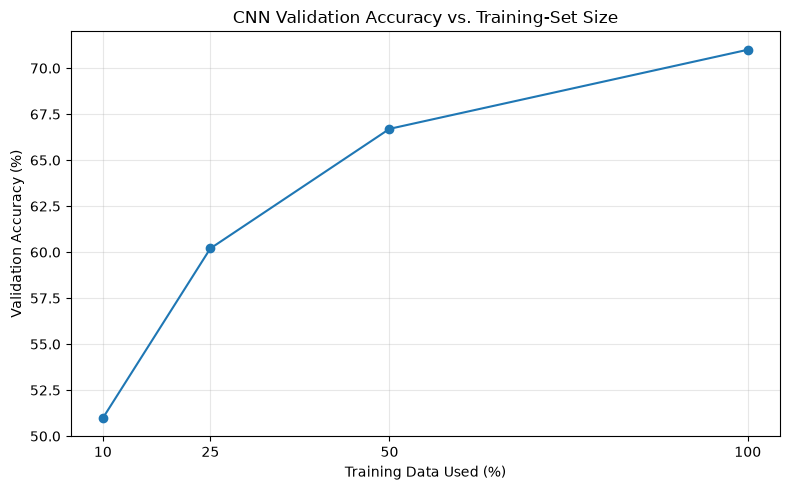

In [15]:
import matplotlib.pyplot as plt

plot_results = final_results.sort_values("training_fraction")

plt.figure(figsize=(8, 5))

plt.plot(
    plot_results["training_fraction"] * 100,
    plot_results["validation_accuracy"] * 100,
    marker="o"
)

plt.xlabel("Training Data Used (%)")
plt.ylabel("Validation Accuracy (%)")
plt.title("CNN Validation Accuracy vs. Training-Set Size")
plt.xticks([10, 25, 50, 100])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/cnn_validation_accuracy_vs_data.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

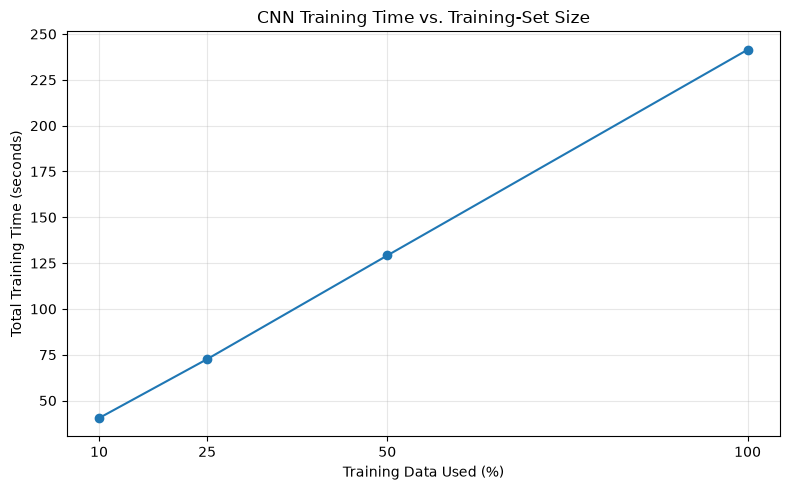

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    plot_results["training_fraction"] * 100,
    plot_results["total_training_seconds"],
    marker="o"
)

plt.xlabel("Training Data Used (%)")
plt.ylabel("Total Training Time (seconds)")
plt.title("CNN Training Time vs. Training-Set Size")
plt.xticks([10, 25, 50, 100])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/cnn_training_time_vs_data.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

17. Learning-Curve Analysis

Learning curves show how training and validation performance change over successive epochs.

Training loss should generally decrease as the model learns. Validation loss and accuracy help assess whether these improvements transfer to unseen data.

Comparing learning curves across training fractions can reveal whether smaller datasets learn more slowly, reach lower performance, or exhibit a larger generalisation gap.

The curves will be interpreted alongside the final metrics rather than used as standalone evidence of generalisation.

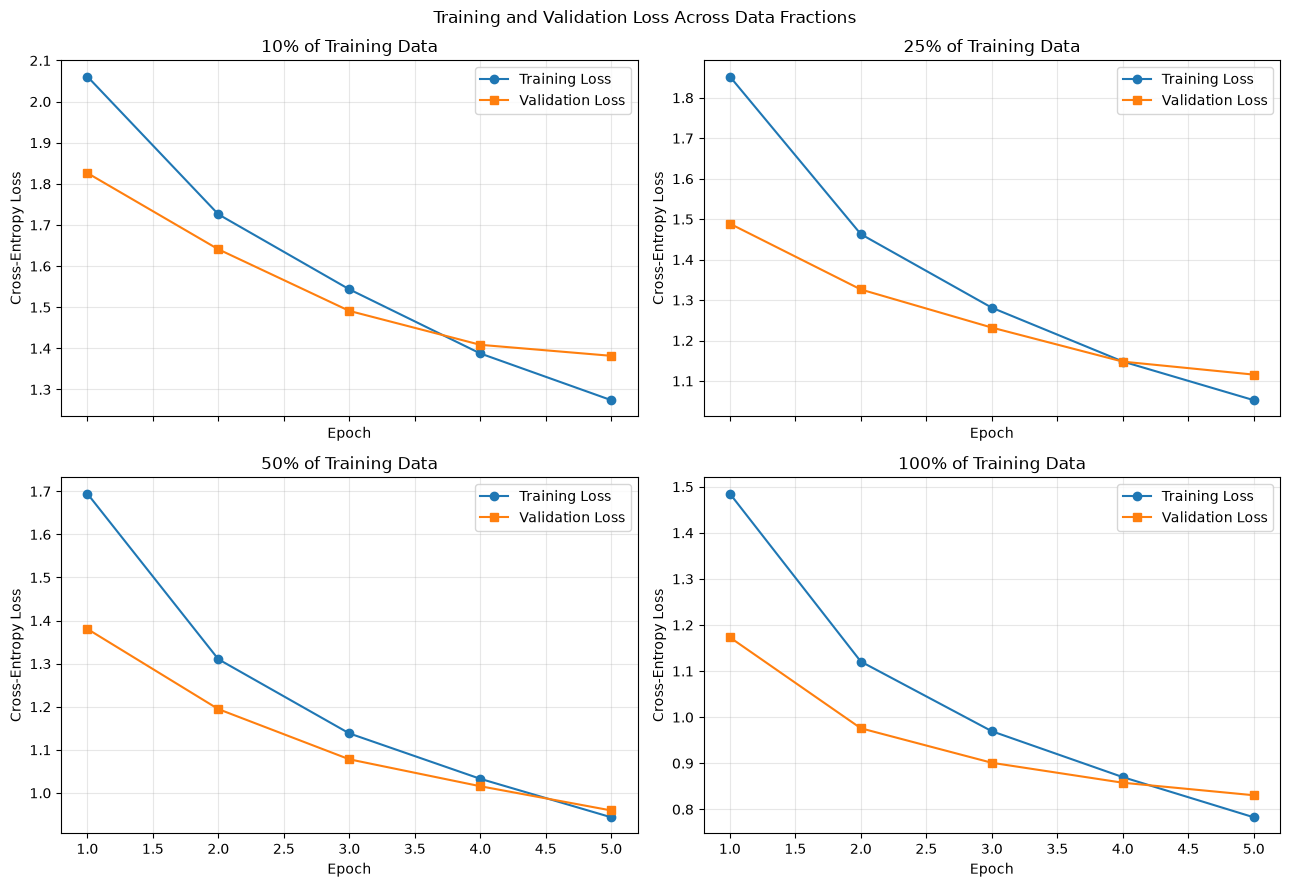

In [17]:
fractions = sorted(experiment_history["training_fraction"].unique())

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharex=True
)

axes = axes.flatten()

for ax, fraction in zip(axes, fractions):
    subset = (
        experiment_history[
            experiment_history["training_fraction"] == fraction
        ]
        .sort_values("epoch")
    )

    ax.plot(
        subset["epoch"],
        subset["train_loss"],
        marker="o",
        label="Training Loss"
    )

    ax.plot(
        subset["epoch"],
        subset["validation_loss"],
        marker="s",
        label="Validation Loss"
    )

    ax.set_title(f"{fraction:.0%} of Training Data")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Training and Validation Loss Across Data Fractions")
fig.tight_layout()

fig.savefig(
    "results/cnn_learning_curves_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

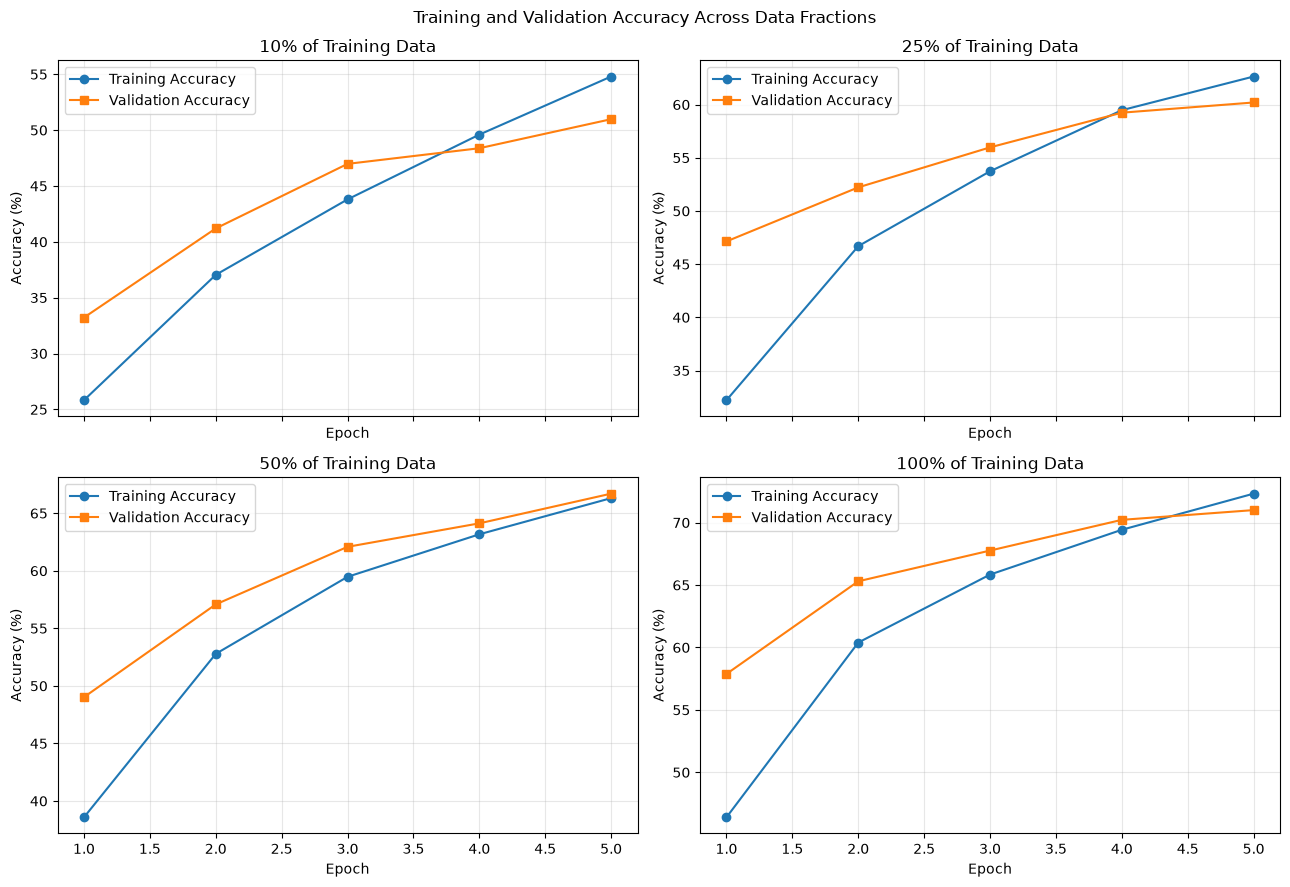

In [18]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharex=True
)

axes = axes.flatten()

for ax, fraction in zip(axes, fractions):
    subset = (
        experiment_history[
            experiment_history["training_fraction"] == fraction
        ]
        .sort_values("epoch")
    )

    ax.plot(
        subset["epoch"],
        subset["train_accuracy"] * 100,
        marker="o",
        label="Training Accuracy"
    )

    ax.plot(
        subset["epoch"],
        subset["validation_accuracy"] * 100,
        marker="s",
        label="Validation Accuracy"
    )

    ax.set_title(f"{fraction:.0%} of Training Data")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Training and Validation Accuracy Across Data Fractions")
fig.tight_layout()

fig.savefig(
    "results/cnn_learning_curves_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

18. Saving the Classical CNN Baseline

The trained CNN models and experiment configuration will be saved to support reproducibility and future comparisons.

The model trained on the full training pool will serve as the principal classical baseline for subsequent experiments.

The saved checkpoint will contain the model parameters, architecture identifier, training configuration, random seed, and final validation metrics.

This checkpoint will support later evaluation and comparison with the hybrid quantum-classical model.

In [19]:
import json

# Select the model trained with 100% of the training pool
full_data_fraction = 1.0
full_data_model = models_by_fraction[full_data_fraction]

full_data_metrics = (
    final_results[
        final_results["training_fraction"] == full_data_fraction
    ]
    .iloc[0]
)

# Save model checkpoint
checkpoint = {
    "model_state_dict": full_data_model.state_dict(),
    "model_name": "ClassicalCNN",
    "dataset": "CIFAR-10",
    "training_fraction": full_data_fraction,
    "training_images": len(train_subsets[full_data_fraction]),
    "validation_images": len(validation_dataset),
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "validation_accuracy": float(
        full_data_metrics["validation_accuracy"]
    ),
    "validation_loss": float(
        full_data_metrics["validation_loss"]
    )
}

torch.save(
    checkpoint,
    "results/classical_cnn_full_data.pt"
)

# Save experiment configuration
config = {
    "dataset": "CIFAR-10",
    "model": "ClassicalCNN",
    "seed": SEED,
    "data_fractions": DATA_FRACTIONS,
    "training_pool_size": len(train_pool),
    "validation_size": len(validation_dataset),
    "test_size": len(test_dataset),
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "device": str(DEVICE)
}

with open(
    "results/experiment_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(config, file, indent=4)

print("Saved full-data classical CNN checkpoint.")
print("Saved experiment configuration.")
print(
    "Full-data validation accuracy:",
    f"{full_data_metrics['validation_accuracy']:.2%}"
)

Saved full-data classical CNN checkpoint.
Saved experiment configuration.
Full-data validation accuracy: 71.00%


19. Baseline Results Analysis

Objective

Analyse the performance of the classical CNN across different training-data fractions to establish a reference point for subsequent Vision Transformer and Hybrid Quantum-Classical Vision Transformer experiments.

Analysis

The experiments evaluate the relationship between training-data quantity, classification accuracy, generalisation, and computational cost.

The following metrics will be examined:

- Final training accuracy and validation accuracy.
- Training and validation loss.
- Generalisation gap between training and validation accuracy.
- Total training time across epochs.

Research Significance

The classical CNN provides a reference for evaluating the performance of subsequent architectures. However, comparisons against a CNN alone cannot isolate the contribution of the quantum component. A classical Vision Transformer baseline is also required.

The observed validation accuracy will be treated as an experimental result rather than evidence that one architecture is inherently superior.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Verify that the experiment results exist
results_path = "results/cnn_data_efficiency_history.csv"

if not os.path.exists(results_path):
    raise FileNotFoundError(
        f"Could not find {results_path}. "
        "Check that Section 14 completed successfully."
    )

experiment_history = pd.read_csv(results_path)

# Select the final epoch of each experiment
final_results = (
    experiment_history
    .sort_values("epoch")
    .groupby("training_fraction")
    .tail(1)
    .sort_values("training_fraction")
    .reset_index(drop=True)
)

# Calculate generalisation gap
final_results["generalisation_gap_pp"] = (
    final_results["train_accuracy"]
    - final_results["validation_accuracy"]
) * 100

# Display baseline summary
baseline_summary = final_results[
    [
        "training_fraction",
        "training_images",
        "train_accuracy",
        "validation_accuracy",
        "train_loss",
        "validation_loss",
        "generalisation_gap_pp"
    ]
].copy()

baseline_summary["train_accuracy"] *= 100
baseline_summary["validation_accuracy"] *= 100

baseline_summary = baseline_summary.rename(columns={
    "training_fraction": "Training Fraction",
    "training_images": "Training Images",
    "train_accuracy": "Train Accuracy (%)",
    "validation_accuracy": "Validation Accuracy (%)",
    "train_loss": "Train Loss",
    "validation_loss": "Validation Loss",
    "generalisation_gap_pp": "Generalisation Gap (pp)"
})

display(baseline_summary.round(3))

# Identify the best validation result
best_row = final_results.loc[
    final_results["validation_accuracy"].idxmax()
]

print(
    f"\nBest training fraction: "
    f"{best_row['training_fraction']:.0%}"
)

print(
    f"Best final validation accuracy: "
    f"{best_row['validation_accuracy']:.2%}"
)

,Training Fraction,Training Images,Train Accuracy (%),Validation Accuracy (%),Train Loss,Validation Loss,Generalisation Gap (pp)
0,0.10,4500,54.800,50.98,1.274,1.382,3.820
1,0.25,11250,62.640,60.20,1.053,1.116,2.440
2,0.50,22500,66.311,66.70,0.943,0.959,-0.389
3,1.00,45000,72.318,71.00,0.783,0.831,1.318



Best training fraction: 100%
Best final validation accuracy: 71.00%


20. Classical Vision Transformer Baseline

Objective

Implement a compact classical Vision Transformer (ViT) to establish a Transformer-based baseline for comparison with the proposed Hybrid Quantum-Classical Vision Transformer.

Architecture

The model will consist of:

1. Patch embedding to convert image regions into token representations.
2. Learnable positional embeddings to retain spatial information.
3. Transformer encoder layers using multi-head self-attention.
4. A classification token to aggregate image-level information.
5. A classification head producing scores for the ten CIFAR-10 classes.

Experimental Controls

The ViT will use the same dataset splits and training-data fractions as the CNN. Its architecture, parameter count, training time, and hyperparameters will be documented.

The classical ViT will later be compared with the hybrid model to help determine whether adding a quantum component provides measurable benefits.

Implementation Note

This is a compact ViT designed for experimentation on 32 × 32 CIFAR-10 images. Its performance must be measured experimentally; it should not be assumed to outperform the CNN.

In [21]:
import torch
import torch.nn as nn


class ClassicalViT(nn.Module):
    def __init__(
        self,
        image_size=32,
        patch_size=4,
        num_classes=10,
        embed_dim=128,
        num_heads=4,
        num_layers=4,
        mlp_dim=256,
        dropout=0.1
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size

        num_patches = (image_size // patch_size) ** 2

        # Convert image patches into embedding vectors
        self.patch_embedding = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # Learnable classification token and positional embeddings
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        self.embedding_dropout = nn.Dropout(dropout)

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(embed_dim)
        )

        # Classification head
        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes)
        )

        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):
        # x: [batch, 3, 32, 32]
        x = self.patch_embedding(x)

        # [batch, embed_dim, grid_h, grid_w]
        x = x.flatten(2).transpose(1, 2)

        # Add classification token
        cls_tokens = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)

        # Add positional embeddings
        x = x + self.pos_embedding
        x = self.embedding_dropout(x)

        # Transformer encoder
        x = self.transformer(x)

        # Classification token representation
        cls_representation = x[:, 0]

        return self.classifier(cls_representation)


# Initialise the model
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

vit_model = ClassicalViT().to(DEVICE)

# Verify the output shape
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images[:8].to(DEVICE)

with torch.no_grad():
    sample_outputs = vit_model(sample_images)

print("Device:", DEVICE)
print("Input shape:", tuple(sample_images.shape))
print("Output shape:", tuple(sample_outputs.shape))
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in vit_model.parameters() if p.requires_grad):,}"
)

assert sample_outputs.shape == (8, 10)
print("ViT forward-pass test passed.")

/tmp/ipykernel_6476/167982418.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Device: cpu
Input shape: (8, 3, 32, 32)
Output shape: (8, 10)
Trainable parameters: 546,442
ViT forward-pass test passed.


Section 21 — Experiment Recovery and Resume

This section checks whether previous CNN experiments have been saved. It allows us to reuse existing results when continuing the project, avoiding unnecessary CNN retraining.

In [22]:
from pathlib import Path
import json
import pandas as pd
import torch

# Project output folders
RESULTS_DIR = Path("results")
MODELS_DIR = Path("models")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Check files created by the CNN experiments
required_files = [
    RESULTS_DIR / "cnn_data_efficiency_history.csv",
    RESULTS_DIR / "cnn_data_efficiency_comparison.csv",
    RESULTS_DIR / "classical_cnn_full_data.pt",
    RESULTS_DIR / "experiment_config.json",
]

print("Previous experiment files:")
for file_path in required_files:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status}: {file_path}")

# Load previous CNN results if available
cnn_history_path = RESULTS_DIR / "cnn_data_efficiency_history.csv"

if cnn_history_path.exists():
    cnn_history = pd.read_csv(cnn_history_path)

    print("\nCNN history loaded successfully.")
    display(cnn_history.tail())

else:
    print(
        "\nCNN history is missing. "
        "Do not rerun the experiment until you check the results folder."
    )

# Load experiment configuration if available
config_path = RESULTS_DIR / "experiment_config.json"

if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as file:
        experiment_config = json.load(file)

    print("\nPrevious experiment configuration:")
    print(json.dumps(experiment_config, indent=2))

Previous experiment files:
FOUND: results/cnn_data_efficiency_history.csv
FOUND: results/cnn_data_efficiency_comparison.csv
FOUND: results/classical_cnn_full_data.pt
FOUND: results/experiment_config.json

CNN history loaded successfully.


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds,training_fraction,training_images
15,1,1.485010,0.464000,1.173173,0.5788,48.545087,1.0,45000
16,2,1.120632,0.603933,0.975915,0.6530,48.361933,1.0,45000
17,3,0.969530,0.658378,0.901063,0.6776,48.279852,1.0,45000
18,4,0.869954,0.694244,0.857775,0.7022,48.256361,1.0,45000
19,5,0.782743,0.723178,0.830620,0.7100,47.979109,1.0,45000



Previous experiment configuration:
{
  "dataset": "CIFAR-10",
  "model": "ClassicalCNN",
  "seed": 42,
  "data_fractions": [
    0.1,
    0.25,
    0.5,
    1.0
  ],
  "training_pool_size": 45000,
  "validation_size": 5000,
  "test_size": 10000,
  "epochs": 5,
  "learning_rate": 0.001,
  "batch_size": 128,
  "device": "cpu"
}


Section 22 — Classical Vision Transformer Training

In this section, the Classical Vision Transformer will be trained using 10%, 25%, 50%, and 100% of the available training pool.

The same validation set will be used for all experiments. Training histories and model checkpoints will be saved so that completed experiments can be reused without retraining.

The initial experiment will use five epochs per data fraction to keep the computational cost manageable.

In [27]:
import time
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

VIT_EPOCHS = 3
VIT_BATCH_SIZE = 128
VIT_LEARNING_RATE = 0.001

vit_histories = {}
vit_models_by_fraction = {}

for fraction in DATA_FRACTIONS:

    percentage = int(fraction * 100)

    history_path = RESULTS_DIR / f"vit_history_{percentage}pct.csv"
    checkpoint_path = MODELS_DIR / f"classical_vit_{percentage}pct.pt"

    # Skip experiments already saved successfully
    if history_path.exists() and checkpoint_path.exists():

        print(f"\nSkipping completed experiment: {percentage}%")

        vit_histories[fraction] = pd.read_csv(history_path)

        vit_models_by_fraction[fraction] = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True
        )

        continue

    print(f"\nTraining Classical ViT with {percentage}% of training data")

    # Reproducibility
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # Fresh model for each data fraction
    model = ClassicalViT().to(DEVICE)

    generator = torch.Generator().manual_seed(SEED)

    fraction_loader = DataLoader(
        train_subsets[fraction],
        batch_size=VIT_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    start_time = time.time()

    # Match your existing function's actual signature
    history = train_model(
        model,
        fraction_loader,
        validation_loader,
        epochs=VIT_EPOCHS,
        lr=VIT_LEARNING_RATE
    )

    total_seconds = time.time() - start_time

    # Save history and experiment metadata
    history["data_fraction"] = fraction
    history["training_samples"] = len(train_subsets[fraction])
    history["total_experiment_seconds"] = total_seconds

    history.to_csv(history_path, index=False)

    # Save model weights
    torch.save(model.state_dict(), checkpoint_path)

    vit_histories[fraction] = history
    vit_models_by_fraction[fraction] = model

    print(f"Completed: {percentage}%")
    print(f"Training time: {total_seconds / 60:.2f} minutes")
    print(f"Saved history: {history_path}")
    print(f"Saved checkpoint: {checkpoint_path}")

# Combine histories from completed and newly trained experiments
vit_history_df = pd.concat(
    [
        history.assign(data_fraction=fraction)
        for fraction, history in vit_histories.items()
    ],
    ignore_index=True
)

vit_history_df.to_csv(
    RESULTS_DIR / "vit_data_efficiency_history.csv",
    index=False
)

print("\nViT experiments completed or recovered.")
display(vit_history_df.tail())


Skipping completed experiment: 10%

Skipping completed experiment: 25%

Skipping completed experiment: 50%

Training Classical ViT with 100% of training data


/tmp/ipykernel_6476/167982418.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Epoch 1/3 | Train loss: 1.7361 | Train acc: 35.19% | Val loss: 1.4591 | Val acc: 45.44% | Time: 310.1s
Epoch 2/3 | Train loss: 1.3989 | Train acc: 48.86% | Val loss: 1.2755 | Val acc: 53.68% | Time: 355.2s
Epoch 3/3 | Train loss: 1.2565 | Train acc: 54.55% | Val loss: 1.2131 | Val acc: 55.54% | Time: 324.7s
Completed: 100%
Training time: 16.50 minutes
Saved history: results/vit_history_100pct.csv
Saved checkpoint: models/classical_vit_100pct.pt

ViT experiments completed or recovered.


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds,data_fraction,training_samples,total_experiment_seconds
7,2,1.587356,0.414444,1.500109,0.4496,163.411192,0.5,22500,489.958798
8,3,1.428716,0.477378,1.379053,0.4862,162.453547,0.5,22500,489.958798
9,1,1.736055,0.351889,1.459144,0.4544,310.103854,1.0,45000,990.058676
10,2,1.398868,0.488556,1.275529,0.5368,355.220676,1.0,45000,990.058676
11,3,1.256452,0.545511,1.213134,0.5554,324.725920,1.0,45000,990.058676


Section 23 — Classical ViT Results Analysis

This section summarises the final training and validation metrics for each data fraction. It helps identify how the amount of training data affects the Vision Transformer's performance and generalisation.

In [28]:
import pandas as pd

vit_history_df = pd.read_csv(
    RESULTS_DIR / "vit_data_efficiency_history.csv"
)

vit_summary_rows = []

for fraction in sorted(vit_history_df["data_fraction"].unique()):

    subset = vit_history_df[
        vit_history_df["data_fraction"] == fraction
    ].sort_values("epoch")

    final_epoch = subset.iloc[-1]

    train_accuracy = float(final_epoch["train_accuracy"])
    validation_accuracy = float(final_epoch["validation_accuracy"])

    vit_summary_rows.append({
        "Data Fraction (%)": int(fraction * 100),
        "Training Samples": int(final_epoch["training_samples"]),
        "Train Accuracy (%)": train_accuracy * 100,
        "Validation Accuracy (%)": validation_accuracy * 100,
        "Generalisation Gap (percentage points)": (
            train_accuracy - validation_accuracy
        ) * 100,
        "Final Train Loss": float(final_epoch["train_loss"]),
        "Final Validation Loss": float(final_epoch["validation_loss"])
    })

vit_summary = pd.DataFrame(vit_summary_rows)

vit_summary.to_csv(
    RESULTS_DIR / "vit_data_efficiency_comparison.csv",
    index=False
)

display(vit_summary.round(3))

best_vit_row = vit_summary.loc[
    vit_summary["Validation Accuracy (%)"].idxmax()
]

print(
    f"\nBest validation accuracy: "
    f"{best_vit_row['Validation Accuracy (%)']:.2f}%"
)

print(
    f"Training data used: "
    f"{best_vit_row['Data Fraction (%)']}%"
)

,Data Fraction (%),Training Samples,Train Accuracy (%),Validation Accuracy (%),Generalisation Gap (percentage points),Final Train Loss,Final Validation Loss
0,10,4500,31.756,33.34,-1.584,1.796,1.791
1,25,11250,39.493,40.86,-1.367,1.624,1.579
2,50,22500,47.738,48.62,-0.882,1.429,1.379
3,100,45000,54.551,55.54,-0.989,1.256,1.213



Best validation accuracy: 55.54%
Training data used: 100.0%


Section 24 — Visualising ViT Data Efficiency

This section plots validation accuracy against the amount of training data used. The graph will help reveal whether increasing the training data consistently improves the model's performance.

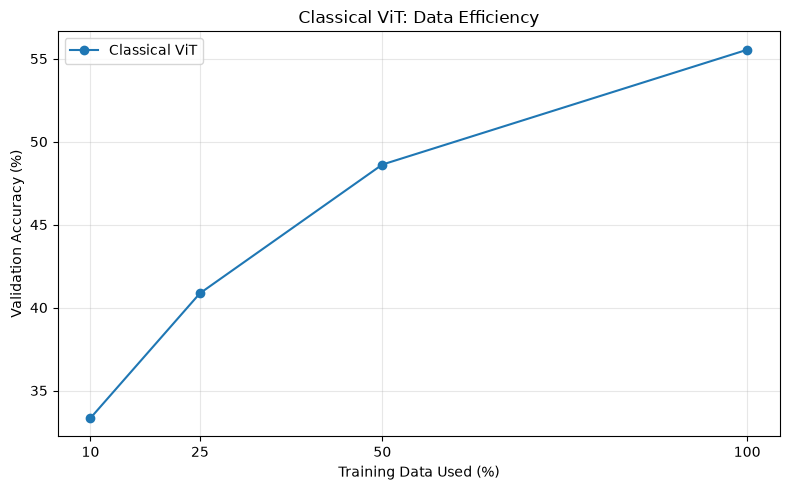

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    vit_summary["Data Fraction (%)"],
    vit_summary["Validation Accuracy (%)"],
    marker="o",
    label="Classical ViT"
)

plt.xlabel("Training Data Used (%)")
plt.ylabel("Validation Accuracy (%)")
plt.title("Classical ViT: Data Efficiency")
plt.xticks([10, 25, 50, 100])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vit_data_efficiency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Section 25 — Quantum Library Setup

This section prepares the environment for implementing a hybrid quantum-classical neural network.

We will use PennyLane to build a parameterised quantum circuit that can integrate with PyTorch. First, we will verify the installation and check whether the required libraries are available.

In [30]:
%pip install pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 13.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 15.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 11.8 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 43.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 36.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [pennylane]12 [pennylane]lightning]
Note: you may need to restart the kernel to use updated packages.


In [31]:
# Check whether PennyLane is installed

try:
    import pennylane as qml
    print("PennyLane version:", qml.__version__)
    print("Quantum library is ready.")

except ImportError:
    print("PennyLane is not installed.")
    print("Install it by running the command below in a separate cell:")
    print("%pip install pennylane")

PennyLane version: 0.45.1
Quantum library is ready.


Section 26 — Parameterised Quantum Circuit

In this section, we will implement a small quantum circuit using PennyLane.

The circuit will encode classical input features into quantum states, apply trainable quantum operations, and measure the resulting states to produce numerical outputs.

These outputs will later be integrated into a classical neural network. We will begin with four qubits to keep simulation computationally manageable.

In [32]:
import pennylane as qml
import torch
import torch.nn as nn

N_QUBITS = 4
N_Q_LAYERS = 2

# Quantum simulator
quantum_device = qml.device(
    "default.qubit",
    wires=N_QUBITS
)

@qml.qnode(quantum_device, interface="torch")
def quantum_circuit(inputs, weights):

    # Encode classical features into quantum states
    for wire in range(N_QUBITS):
        qml.RY(inputs[wire], wires=wire)

    # Trainable quantum layers
    for layer in range(N_Q_LAYERS):

        for wire in range(N_QUBITS):
            qml.RY(
                weights[layer, wire, 0],
                wires=wire
            )

            qml.RZ(
                weights[layer, wire, 1],
                wires=wire
            )

        # Entangle neighbouring qubits
        for wire in range(N_QUBITS - 1):
            qml.CNOT(
                wires=[wire, wire + 1]
            )

    # Measure each qubit
    return [
        qml.expval(qml.PauliZ(wire))
        for wire in range(N_QUBITS)
    ]


# Test the circuit
test_inputs = torch.tensor(
    [0.1, 0.2, 0.3, 0.4],
    dtype=torch.float32
)

test_weights = torch.randn(
    N_Q_LAYERS,
    N_QUBITS,
    2,
    dtype=torch.float32
)

test_output = quantum_circuit(
    test_inputs,
    test_weights
)

print("Quantum circuit output:")
print(test_output)

Quantum circuit output:
[tensor(-0.0165, dtype=torch.float64), tensor(0.3187, dtype=torch.float64), tensor(-0.0103, dtype=torch.float64), tensor(0.2860, dtype=torch.float64)]


Section 27 — Quantum Gradient Test

Hybrid quantum-classical models require gradients to update trainable parameters during backpropagation.

This section checks whether the quantum circuit produces gradients for its trainable quantum parameters. Successful gradient computation is a prerequisite for integrating the circuit into a trainable model.

In [33]:
# Create trainable quantum parameters
test_weights = torch.randn(
    N_Q_LAYERS,
    N_QUBITS,
    2,
    dtype=torch.float32,
    requires_grad=True
)

test_inputs = torch.tensor(
    [0.1, 0.2, 0.3, 0.4],
    dtype=torch.float32
)

# Calculate circuit output
output = quantum_circuit(
    test_inputs,
    test_weights
)

# Convert measurements to a tensor
output_tensor = torch.stack(output)

# Define a simple scalar objective
loss = output_tensor.sum()

# Backpropagate
loss.backward()

print("Output:", output_tensor.detach())
print("Gradient exists:", test_weights.grad is not None)

if test_weights.grad is not None:
    print("Gradient shape:", test_weights.grad.shape)
    print("Gradient finite:", torch.isfinite(test_weights.grad).all().item())

Output: tensor([ 0.2010, -0.3980, -0.0588, -0.0349], dtype=torch.float64)
Gradient exists: True
Gradient shape: torch.Size([2, 4, 2])
Gradient finite: True


Section 28 — Hybrid Quantum-Classical Vision Model

This section combines a classical neural network with a parameterised quantum circuit.

The classical feature extractor reduces each input image to four features. These features are encoded into a four-qubit quantum circuit, which produces four measurement values. A classical classification head then uses these measurements to predict one of the ten CIFAR-10 classes.

This compact architecture provides a practical starting point for investigating hybrid quantum-classical learning under limited-data conditions.

In [34]:
import torch
import torch.nn as nn
import pennylane as qml

class HybridQuantumClassifier(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        self.feature_extractor = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),

            nn.Linear(32, 4),
            nn.Tanh()
        )

        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(N_Q_LAYERS, N_QUBITS, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, num_classes)
        )

    def forward(self, images):

        features = self.feature_extractor(images)

        # Scale features into rotation angles
        angles = torch.pi * features

        quantum_outputs = []

        for sample in angles:
            q_out = quantum_circuit(
                sample,
                self.quantum_weights
            )

            quantum_outputs.append(
                torch.stack(q_out)
            )

        quantum_outputs = torch.stack(quantum_outputs).to(
            device=images.device,
            dtype=images.dtype
        )

        logits = self.classifier(quantum_outputs)

        return logits


# Check the output dimensions
hybrid_model = HybridQuantumClassifier().to(DEVICE)

test_batch = torch.randn(2, 3, 32, 32).to(DEVICE)

with torch.no_grad():
    test_predictions = hybrid_model(test_batch)

print("Input shape:", test_batch.shape)
print("Output shape:", test_predictions.shape)
print("Expected output shape: (2, 10)")
print("Total trainable parameters:",
      sum(p.numel() for p in hybrid_model.parameters() if p.requires_grad))

Input shape: torch.Size([2, 3, 32, 32])
Output shape: torch.Size([2, 10])
Expected output shape: (2, 10)
Total trainable parameters: 5726


Section 29 — End-to-End Gradient Verification

Before training, we must verify that the loss can backpropagate through the classical feature extractor, quantum circuit, and final classifier.

This test checks whether the hybrid architecture supports the gradient-based optimisation required for training.

In [35]:
hybrid_model = HybridQuantumClassifier().to(DEVICE)
hybrid_model.train()

test_images = torch.randn(2, 3, 32, 32).to(DEVICE)
test_labels = torch.tensor([0, 1], dtype=torch.long).to(DEVICE)

criterion = nn.CrossEntropyLoss()

predictions = hybrid_model(test_images)
loss = criterion(predictions, test_labels)

loss.backward()

print("Test loss:", loss.item())

print(
    "Feature extractor gradient exists:",
    any(
        p.grad is not None
        for p in hybrid_model.feature_extractor.parameters()
    )
)

print(
    "Quantum parameters gradient exists:",
    hybrid_model.quantum_weights.grad is not None
)

print(
    "Classifier gradient exists:",
    any(
        p.grad is not None
        for p in hybrid_model.classifier.parameters()
    )
)

if hybrid_model.quantum_weights.grad is not None:
    print(
        "Quantum gradients finite:",
        torch.isfinite(hybrid_model.quantum_weights.grad).all().item()
    )

Test loss: 2.148083448410034
Feature extractor gradient exists: True
Quantum parameters gradient exists: True
Classifier gradient exists: True
Quantum gradients finite: True


Section 30 — Hybrid Model Training Smoke Test

This section performs a short training experiment using a small subset of CIFAR-10.

The purpose is to verify that the hybrid model can complete forward passes, backpropagation, parameter updates, and validation without errors.

This is a functionality test, not a final performance evaluation. The results will help determine whether the model is ready for the full data-efficiency experiments.

In [36]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

# Use a small subset to test training speed
SMOKE_TRAIN_SIZE = min(256, len(train_subsets[0.10]))
SMOKE_VAL_SIZE = min(128, len(validation_dataset))

smoke_train_dataset = Subset(
    train_subsets[0.10],
    range(SMOKE_TRAIN_SIZE)
)

smoke_val_dataset = Subset(
    validation_dataset,
    range(SMOKE_VAL_SIZE)
)

smoke_train_loader = DataLoader(
    smoke_train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

smoke_val_loader = DataLoader(
    smoke_val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

smoke_model = HybridQuantumClassifier().to(DEVICE)

smoke_optimizer = torch.optim.Adam(
    smoke_model.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss()

# Run one training epoch
smoke_model.train()
running_loss = 0.0
correct = 0
total = 0

start_time = time.time()

for images, labels in smoke_train_loader:

    images = images.to(DEVICE)
    labels = labels.to(DEVICE)

    smoke_optimizer.zero_grad()

    outputs = smoke_model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    smoke_optimizer.step()

    running_loss += loss.item() * images.size(0)

    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

train_loss = running_loss / total
train_accuracy = correct / total

# Validate
smoke_model.eval()
val_loss_sum = 0.0
val_correct = 0
val_total = 0

with torch.no_grad():
    for images, labels in smoke_val_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = smoke_model(images)
        loss = criterion(outputs, labels)

        val_loss_sum += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        val_correct += (predictions == labels).sum().item()
        val_total += labels.size(0)

validation_loss = val_loss_sum / val_total
validation_accuracy = val_correct / val_total

elapsed = time.time() - start_time

print("Hybrid smoke test completed.")
print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_accuracy * 100:.2f}%")
print(f"Validation loss: {validation_loss:.4f}")
print(f"Validation accuracy: {validation_accuracy * 100:.2f}%")
print(f"Elapsed time: {elapsed:.2f} seconds")

Hybrid smoke test completed.
Training loss: 2.3343
Training accuracy: 13.67%
Validation loss: 2.3156
Validation accuracy: 10.94%
Elapsed time: 5.33 seconds


Section 31 — Save Hybrid Smoke-Test Results

This section records the preliminary training and validation metrics, together with the elapsed time.

Saving these results allows us to document the initial functionality test without confusing it with the final experimental results.

In [37]:
import json
from pathlib import Path

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

smoke_results = {
    "experiment": "hybrid_smoke_test",
    "training_samples": SMOKE_TRAIN_SIZE,
    "validation_samples": SMOKE_VAL_SIZE,
    "epochs": 1,
    "batch_size": 16,
    "learning_rate": 0.001,
    "training_loss": train_loss,
    "training_accuracy": train_accuracy,
    "validation_loss": validation_loss,
    "validation_accuracy": validation_accuracy,
    "elapsed_seconds": elapsed,
    "device": str(DEVICE),
    "num_qubits": N_QUBITS,
    "quantum_layers": N_Q_LAYERS
}

with open(
    RESULTS_DIR / "hybrid_smoke_test.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(smoke_results, file, indent=2)

torch.save(
    smoke_model.state_dict(),
    MODELS_DIR / "hybrid_smoke_test.pt"
)

print("Smoke-test metrics saved.")
print("Metrics:", RESULTS_DIR / "hybrid_smoke_test.json")
print("Checkpoint:", MODELS_DIR / "hybrid_smoke_test.pt")

Smoke-test metrics saved.
Metrics: results/hybrid_smoke_test.json
Checkpoint: models/hybrid_smoke_test.pt


Section 32 — Hybrid Model Data-Efficiency Experiment

This section trains the Hybrid Quantum-Classical Vision Transformer using different fractions of the CIFAR-10 training pool.

The experiments will use the same training subsets and validation set as the classical baselines. Each completed experiment will save its model checkpoint and training history.

Because quantum circuit simulation is computationally expensive, we will begin with the 10% data fraction and evaluate the training time before proceeding to larger fractions.

In [38]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

HQ_EPOCHS = 3
HQ_BATCH_SIZE = 16
HQ_LEARNING_RATE = 0.001

# Start with only 10% to assess the cost
HQ_FRACTIONS_TO_RUN = [0.10]

hq_histories = {}
hq_models_by_fraction = {}

criterion = nn.CrossEntropyLoss()

for fraction in HQ_FRACTIONS_TO_RUN:

    percentage = int(fraction * 100)

    history_path = RESULTS_DIR / f"hqvit_history_{percentage}pct.csv"
    checkpoint_path = MODELS_DIR / f"hqvit_{percentage}pct.pt"

    # Reuse completed experiments
    if history_path.exists() and checkpoint_path.exists():
        print(f"\nReusing completed HQViT experiment: {percentage}%")

        hq_histories[fraction] = pd.read_csv(history_path)

        hq_models_by_fraction[fraction] = HybridQuantumClassifier().to(DEVICE)
        hq_models_by_fraction[fraction].load_state_dict(
            torch.load(
                checkpoint_path,
                map_location=DEVICE,
                weights_only=True
            )
        )
        continue

    print(f"\nTraining HQViT with {percentage}% of training data")

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = HybridQuantumClassifier().to(DEVICE)

    generator = torch.Generator().manual_seed(SEED)

    fraction_loader = DataLoader(
        train_subsets[fraction],
        batch_size=HQ_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=HQ_LEARNING_RATE
    )

    rows = []
    start_experiment = time.time()

    for epoch in range(1, HQ_EPOCHS + 1):

        epoch_start = time.time()
        model.train()

        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in fraction_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * images.size(0)
            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            train_total += labels.size(0)

        train_loss = train_loss_sum / train_total
        train_accuracy = train_correct / train_total

        # Validation
        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in validation_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * images.size(0)
                val_correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()
                val_total += labels.size(0)

        validation_loss = val_loss_sum / val_total
        validation_accuracy = val_correct / val_total

        epoch_seconds = time.time() - epoch_start

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "epoch_seconds": epoch_seconds,
            "data_fraction": fraction,
            "training_samples": len(train_subsets[fraction])
        }

        rows.append(row)

        # Save after every epoch so completed epochs are recorded
        pd.DataFrame(rows).to_csv(history_path, index=False)
        torch.save(model.state_dict(), checkpoint_path)

        print(
            f"Epoch {epoch}/{HQ_EPOCHS} | "
            f"Train acc: {train_accuracy:.4f} | "
            f"Val acc: {validation_accuracy:.4f} | "
            f"Time: {epoch_seconds / 60:.2f} min"
        )

    total_seconds = time.time() - start_experiment

    history = pd.DataFrame(rows)
    history["total_experiment_seconds"] = total_seconds

    history.to_csv(history_path, index=False)
    torch.save(model.state_dict(), checkpoint_path)

    hq_histories[fraction] = history
    hq_models_by_fraction[fraction] = model

    print(f"\nCompleted {percentage}% HQViT experiment.")
    print(f"Total time: {total_seconds / 60:.2f} minutes")
    print(f"History saved to: {history_path}")
    print(f"Checkpoint saved to: {checkpoint_path}")

print("\nHQViT experiment run finished.")


Training HQViT with 10% of training data
Epoch 1/3 | Train acc: 0.1400 | Val acc: 0.1934 | Time: 1.81 min
Epoch 2/3 | Train acc: 0.2282 | Val acc: 0.2562 | Time: 1.65 min
Epoch 3/3 | Train acc: 0.2431 | Val acc: 0.2596 | Time: 1.61 min

Completed 10% HQViT experiment.
Total time: 5.07 minutes
History saved to: results/hqvit_history_10pct.csv
Checkpoint saved to: models/hqvit_10pct.pt

HQViT experiment run finished.


Section 33 — HQViT Results Analysis

This section summarises the available HQViT training results. It reports the final training and validation accuracy, loss, generalisation gap, and training time.

These initial results will be used to assess whether the hybrid model is practical to train before expanding the experiment to larger data fractions.

In [39]:
from pathlib import Path
import pandas as pd

hq_rows = []

for fraction in DATA_FRACTIONS:

    percentage = int(fraction * 100)
    history_path = RESULTS_DIR / f"hqvit_history_{percentage}pct.csv"

    if not history_path.exists():
        print(f"Not yet available: {percentage}% HQViT")
        continue

    history = pd.read_csv(history_path)

    if history.empty:
        print(f"No completed epochs found for {percentage}% HQViT")
        continue

    final_epoch = history.sort_values("epoch").iloc[-1]

    hq_rows.append({
        "Data Fraction (%)": percentage,
        "Training Samples": int(final_epoch["training_samples"]),
        "Completed Epochs": int(final_epoch["epoch"]),
        "Train Accuracy (%)": final_epoch["train_accuracy"] * 100,
        "Validation Accuracy (%)": final_epoch["validation_accuracy"] * 100,
        "Generalisation Gap (pp)": (
            final_epoch["train_accuracy"]
            - final_epoch["validation_accuracy"]
        ) * 100,
        "Train Loss": final_epoch["train_loss"],
        "Validation Loss": final_epoch["validation_loss"],
        "Epoch Time (seconds)": final_epoch["epoch_seconds"]
    })

hq_summary = pd.DataFrame(hq_rows)

if not hq_summary.empty:
    hq_summary.to_csv(
        RESULTS_DIR / "hqvit_data_efficiency_comparison.csv",
        index=False
    )
    display(hq_summary.round(4))
else:
    print("No HQViT experiment results are available yet.")

Not yet available: 25% HQViT
Not yet available: 50% HQViT
Not yet available: 100% HQViT


,Data Fraction (%),Training Samples,Completed Epochs,Train Accuracy (%),Validation Accuracy (%),Generalisation Gap (pp),Train Loss,Validation Loss,Epoch Time (seconds)
0,10,4500,3,24.3111,25.96,-1.6489,1.9096,1.8968,96.5911


Section 34 — HQViT Learning Curves

This section plots training and validation accuracy across epochs for each available HQViT experiment. These curves help show whether the model is learning and whether its validation performance improves during training.

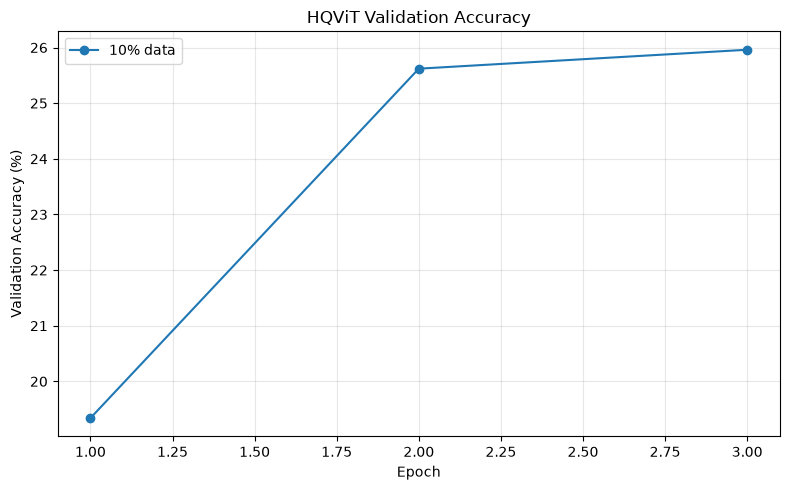

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for fraction in DATA_FRACTIONS:

    percentage = int(fraction * 100)
    history_path = RESULTS_DIR / f"hqvit_history_{percentage}pct.csv"

    if not history_path.exists():
        continue

    history = pd.read_csv(history_path)

    plt.plot(
        history["epoch"],
        history["validation_accuracy"] * 100,
        marker="o",
        label=f"{percentage}% data"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("HQViT Validation Accuracy")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "hqvit_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Section 35: Hybrid Quantum-Classical Vision Transformer Architecture

### Objective
Develop a genuine Hybrid Quantum-Classical Vision Transformer (HQViT)
by integrating a parameterized quantum circuit into a classical Vision
Transformer architecture.

### Architecture
1. Patch embedding: Convert CIFAR-10 images into patch embeddings.
2. Transformer encoder: Learn contextual representations between patches.
3. Quantum projection: Reduce the transformer representation to four
   quantum input features.
4. Quantum circuit: Process the features using a parameterized four-qubit
   variational quantum circuit.
5. Classification head: Map the quantum outputs to ten CIFAR-10 classes.

### Research objective
Investigate whether integrating a quantum circuit into a Vision Transformer
affects classification accuracy, generalisation, and training efficiency
under different training-data budgets.

The hybrid model will be evaluated against the existing classical CNN
and classical ViT baselines.

In [41]:
import torch
import torch.nn as nn
import pennylane as qml

print("PyTorch:", torch.__version__)
print("PennyLane:", qml.__version__)
print("Device:", DEVICE)

assert "ClassicalViT" in globals(), (
    "ClassicalViT is not defined. Run the earlier ViT definition cell."
)

assert "quantum_circuit" in globals(), (
    "quantum_circuit is not defined. Run the earlier quantum circuit cell."
)

assert "N_QUBITS" in globals(), "N_QUBITS is not defined."
assert "N_Q_LAYERS" in globals(), "N_Q_LAYERS is not defined."

print("\nRequired components are available.")
print("We can now build the integrated HQViT.")

PyTorch: 2.14.1+cu130
PennyLane: 0.45.1
Device: cpu

Required components are available.
We can now build the integrated HQViT.


## Section 36: Implement the Hybrid Quantum-Classical Vision Transformer

The model uses a Vision Transformer to extract contextual image
representations. Its class-token representation is projected into four
features, which are encoded into a four-qubit quantum circuit.

The expectation values measured from the quantum circuit are passed
through a classical classification head to predict one of ten classes.

The transformer and classical layers are trained jointly with the
variational quantum circuit parameters using backpropagation.

The model will use the existing quantum circuit and CIFAR-10 setup.

In [42]:
class HybridQuantumViT(nn.Module):
    """
    Vision Transformer with a variational quantum classification component.

    Uses the existing quantum_circuit, N_QUBITS, and N_Q_LAYERS.
    """

    def __init__(self, num_classes=10):
        super().__init__()

        # Classical ViT backbone
        self.vit = ClassicalViT(num_classes=num_classes)

        # Access the ViT's transformer representation.
        # This implementation assumes the ViT exposes:
        # patch_embed, cls_token, pos_embed, transformer, and norm.
        required = [
            "patch_embed",
            "cls_token",
            "pos_embed",
            "transformer",
            "norm",
        ]

        missing = [
            name for name in required
            if not hasattr(self.vit, name)
        ]

        if missing:
            raise AttributeError(
                "The existing ClassicalViT does not expose these "
                f"components: {missing}. Inspect its definition before "
                "adapting the integration."
            )

        # Determine transformer embedding dimension from class token.
        embed_dim = self.vit.cls_token.shape[-1]

        # Project the class-token representation to quantum input features.
        self.quantum_projection = nn.Sequential(
            nn.Linear(embed_dim, N_QUBITS),
            nn.Tanh()
        )

        # Trainable variational quantum circuit parameters.
        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(N_Q_LAYERS, N_QUBITS, 2)
        )

        # Classification head uses measured quantum expectation values.
        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(32, num_classes)
        )

    def forward(self, images):
        # Patch embedding
        tokens = self.vit.patch_embed(images)

        # Support either [batch, tokens, embedding] or
        # [batch, embedding, height, width] patch embeddings.
        if tokens.ndim == 4:
            tokens = tokens.flatten(2).transpose(1, 2)

        batch_size = tokens.shape[0]

        # Add class token and positional embeddings.
        cls_tokens = self.vit.cls_token.expand(batch_size, -1, -1)
        tokens = torch.cat([cls_tokens, tokens], dim=1)

        tokens = tokens + self.vit.pos_embed[:, :tokens.shape[1], :]

        # Transformer encoder
        tokens = self.vit.transformer(tokens)

        # Class-token representation
        representation = self.vit.norm(tokens[:, 0])

        # Map to the quantum circuit's input dimension.
        quantum_inputs = torch.pi * self.quantum_projection(representation)

        # Process each sample through the quantum circuit.
        quantum_outputs = []

        for sample in quantum_inputs:
            output = quantum_circuit(sample, self.quantum_weights)
            quantum_outputs.append(output)

        quantum_outputs = torch.stack(quantum_outputs).to(
            device=images.device,
            dtype=images.dtype
        )

        return self.classifier(quantum_outputs)


print("HybridQuantumViT class defined.")

HybridQuantumViT class defined.


## Section 37: Inspect ViT Components

Before testing the integrated HQViT, inspect the existing Vision
Transformer's layers and parameter shapes.

This verifies whether the new model can reuse its patch embedding,
class token, positional embeddings, transformer encoder, and normalization
layers without modifying the established baseline.

In [43]:
vit_inspection = ClassicalViT()

print(vit_inspection)
print("\nTop-level component names:")

for name, module in vit_inspection.named_children():
    print(f"- {name}: {type(module).__name__}")

print("\nRelevant attributes:")

for name in [
    "patch_embed",
    "cls_token",
    "pos_embed",
    "transformer",
    "norm",
    "head",
    "classifier",
]:
    if hasattr(vit_inspection, name):
        value = getattr(vit_inspection, name)

        if isinstance(value, torch.Tensor):
            print(f"{name}: tensor shape {tuple(value.shape)}")
        else:
            print(f"{name}: {type(value).__name__}")
    else:
        print(f"{name}: not present")

ClassicalViT(
  (patch_embedding): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
  (embedding_dropout): Dropout(p=0.1, inplace=False)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
    (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (classifier): Sequential(
    (0): LayerNorm((128,),

/tmp/ipykernel_6476/167982418.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


## Section 38: HQViT Compatibility and Smoke Test

### Objective
Verify that the integrated Hybrid Quantum-Classical Vision Transformer
can perform a forward pass and propagate gradients through its classical
and quantum components.

### Tests
1. Instantiate the model.
2. Pass a small batch of CIFAR-10 images through it.
3. Verify that the output has ten class logits per image.
4. Check that the loss is finite.
5. Confirm that gradients reach the transformer, quantum parameters,
   quantum projection, and classifier.

Training on the full dataset will only begin after these tests pass.

In [46]:
import torch
import torch.nn as nn
import pennylane as qml


class HybridQuantumViT(nn.Module):
    """
    Hybrid Quantum-Classical Vision Transformer.

    Reuses the existing ClassicalViT patch embedding, class token,
    positional embedding, transformer encoder, and final normalization.
    Replaces the original classical classification head with a quantum
    circuit and a new classical classification head.
    """

    def __init__(self, num_classes=10):
        super().__init__()

        self.vit = ClassicalViT(num_classes=num_classes)

        # Project the ViT class-token embedding to N_QUBITS features.
        self.quantum_projection = nn.Sequential(
            nn.Linear(128, N_QUBITS),
            nn.Tanh()
        )

        # Trainable variational quantum circuit parameters.
        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(
                N_Q_LAYERS,
                N_QUBITS,
                2
            )
        )

        # Classical classifier operating on quantum measurements.
        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(32, num_classes)
        )

    def forward(self, images):
        # Patch embedding:
        # [batch, channels, height, width]
        # -> [batch, embedding_dim, patch_height, patch_width]
        tokens = self.vit.patch_embedding(images)

        # Convert spatial patches into a token sequence.
        tokens = tokens.flatten(2).transpose(1, 2)

        # Add class token.
        batch_size = tokens.shape[0]

        cls_tokens = self.vit.cls_token.expand(
            batch_size, -1, -1
        )

        tokens = torch.cat(
            [cls_tokens, tokens],
            dim=1
        )

        # Add positional embeddings.
        tokens = tokens + self.vit.pos_embedding[
            :, :tokens.shape[1], :
        ]

        tokens = self.vit.embedding_dropout(tokens)

        # Transformer contextual representation.
        tokens = self.vit.transformer(tokens)

        # Apply the Transformer's final normalization.
        tokens = self.vit.transformer.norm(tokens)

        # Extract the class-token representation.
        cls_representation = tokens[:, 0, :]

        # Project 128 features to the quantum input dimension.
        quantum_inputs = torch.pi * self.quantum_projection(
            cls_representation
        )

        # Process each image using the parameterized quantum circuit.
        quantum_outputs = []

        for sample in quantum_inputs:
            result = quantum_circuit(
                sample,
                self.quantum_weights
            )

            quantum_outputs.append(result)

        quantum_outputs = torch.stack(
            quantum_outputs,
            dim=0
        )

        quantum_outputs = quantum_outputs.to(
            device=images.device,
            dtype=images.dtype
        )

        return self.classifier(quantum_outputs)


print("Corrected HybridQuantumViT class defined.")

Corrected HybridQuantumViT class defined.


## Section 39: HQViT defination loader

In [48]:
class HybridQuantumViT(nn.Module):
    """
    Hybrid Quantum-Classical Vision Transformer using the existing ViT
    backbone and parameterized quantum circuit.
    """

    def __init__(self, num_classes=10):
        super().__init__()

        self.vit = ClassicalViT(num_classes=num_classes)

        self.quantum_projection = nn.Sequential(
            nn.Linear(128, N_QUBITS),
            nn.Tanh()
        )

        self.quantum_weights = nn.Parameter(
            0.01 * torch.randn(
                N_Q_LAYERS,
                N_QUBITS,
                2
            )
        )

        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(32, num_classes)
        )

    def forward(self, images):
        # Patch embedding
        tokens = self.vit.patch_embedding(images)
        tokens = tokens.flatten(2).transpose(1, 2)

        # Class token and positional embeddings
        batch_size = tokens.shape[0]

        cls_tokens = self.vit.cls_token.expand(
            batch_size, -1, -1
        )

        tokens = torch.cat([cls_tokens, tokens], dim=1)

        tokens = tokens + self.vit.pos_embedding[
            :, :tokens.shape[1], :
        ]

        tokens = self.vit.embedding_dropout(tokens)

        # Transformer encoder and normalization
        tokens = self.vit.transformer(tokens)
        tokens = self.vit.transformer.norm(tokens)

        # Class-token representation
        representation = tokens[:, 0, :]

        # Quantum input features
        quantum_inputs = torch.pi * self.quantum_projection(
            representation
        )

        quantum_outputs = []

        for sample in quantum_inputs:
            result = quantum_circuit(
                sample,
                self.quantum_weights
            )

            # PennyLane may return a list or tuple of measurement values.
            if isinstance(result, (list, tuple)):
                result = torch.stack([
                    value if isinstance(value, torch.Tensor)
                    else torch.as_tensor(
                        value,
                        device=sample.device,
                        dtype=sample.dtype
                    )
                    for value in result
                ])

            elif not isinstance(result, torch.Tensor):
                result = torch.as_tensor(
                    result,
                    device=sample.device,
                    dtype=sample.dtype
                )

            quantum_outputs.append(result.reshape(-1))

        quantum_outputs = torch.stack(quantum_outputs, dim=0)

        quantum_outputs = quantum_outputs.to(
            device=images.device,
            dtype=images.dtype
        )

        return self.classifier(quantum_outputs)


print("Corrected HybridQuantumViT definition loaded.")

Corrected HybridQuantumViT definition loaded.


Section 40: HQViT Forward and Backward Validation

Objective: Verify that the integrated Hybrid Quantum-Classical Vision Transformer produces valid predictions and supports gradient-based training.

The validation checks:

- Output shape for ten CIFAR-10 classes.
- Finite cross-entropy loss.
- Gradient flow through the transformer, quantum projection, quantum circuit parameters, and classification head.

Training will begin only after these checks pass.

In [49]:
hqvit_model = HybridQuantumViT(num_classes=10).to(DEVICE)

images, labels = next(iter(validation_loader))
images = images[:2].to(DEVICE)
labels = labels[:2].to(DEVICE)

hqvit_model.train()
hqvit_model.zero_grad(set_to_none=True)

logits = hqvit_model(images)

assert logits.shape == (2, 10), (
    f"Unexpected output shape: {tuple(logits.shape)}"
)

loss = nn.CrossEntropyLoss()(logits, labels)

assert torch.isfinite(loss).item(), "Loss is not finite."

loss.backward()

gradient_checks = {
    "Transformer": next(
        hqvit_model.vit.transformer.parameters()
    ).grad,
    "Quantum projection": next(
        hqvit_model.quantum_projection.parameters()
    ).grad,
    "Quantum circuit": hqvit_model.quantum_weights.grad,
    "Classification head": next(
        hqvit_model.classifier.parameters()
    ).grad,
}

all_passed = True

print("Output shape:", tuple(logits.shape))
print("Test loss:", round(loss.item(), 4))

for name, grad in gradient_checks.items():
    passed = (
        grad is not None
        and torch.isfinite(grad).all().item()
        and grad.abs().sum().item() > 0
    )

    print(f"{name} gradient check: {passed}")
    all_passed = all_passed and passed

assert all_passed, "At least one gradient check failed."

print("\nHQViT validation passed.")

/tmp/ipykernel_6476/167982418.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Output shape: (2, 10)
Test loss: 2.1523
Transformer gradient check: True
Quantum projection gradient check: True
Quantum circuit gradient check: True
Classification head gradient check: True

HQViT validation passed.


Section 41: Save the HQViT Initialization Checkpoint

Save the integrated model's initial parameters and configuration before training.

This checkpoint is for recovery and reproducibility. It is not a trained model and must not be used as a final performance result.

In [50]:
import os
import json

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

checkpoint_path = "models/hqvit_integrated_initial.pt"
config_path = "results/hqvit_integrated_config.json"

torch.save(
    {
        "model_state_dict": hqvit_model.state_dict(),
        "architecture": "HybridQuantumViT",
        "num_classes": 10,
        "embedding_dim": 128,
        "transformer_layers": 4,
        "num_qubits": N_QUBITS,
        "num_quantum_layers": N_Q_LAYERS,
        "status": "initialized_not_trained",
    },
    checkpoint_path,
)

config = {
    "architecture": "HybridQuantumViT",
    "dataset": "CIFAR-10",
    "num_classes": 10,
    "embedding_dim": 128,
    "transformer_layers": 4,
    "num_qubits": N_QUBITS,
    "num_quantum_layers": N_Q_LAYERS,
    "training_fractions": DATA_FRACTIONS,
    "status": "initialized_not_trained",
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("Initial checkpoint saved:", checkpoint_path)
print("Configuration saved:", config_path)

Initial checkpoint saved: models/hqvit_integrated_initial.pt
Configuration saved: results/hqvit_integrated_config.json


Section 42: Configure HQViT Data-Efficiency Experiment

Objective: Prepare the first integrated HQViT training experiment using 10% of the CIFAR-10 training pool.

The experiment uses:

- Training fraction: 10% (4,500 images).
- Epochs: 3.
- Optimizer: Adam.
- Learning rate: 0.001.
- Loss function: Cross-entropy.
- Validation: The existing 5,000-image validation set.

Training history and model checkpoints will be saved to disk for reproducibility.

In [51]:
from torch.utils.data import DataLoader, Subset
import time
import pandas as pd

HQVIT_FRACTION = 0.10
HQVIT_EPOCHS = 3
HQVIT_BATCH_SIZE = 16
HQVIT_LR = 0.001

hqvit_train_subset = train_subsets[HQVIT_FRACTION]

hqvit_train_loader = DataLoader(
    hqvit_train_subset,
    batch_size=HQVIT_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

print("Training fraction:", f"{HQVIT_FRACTION:.0%}")
print("Training images:", len(hqvit_train_subset))
print("Batch size:", HQVIT_BATCH_SIZE)
print("Epochs:", HQVIT_EPOCHS)
print("Learning rate:", HQVIT_LR)
print("Training batches per epoch:", len(hqvit_train_loader))

Training fraction: 10%
Training images: 4500
Batch size: 16
Epochs: 3
Learning rate: 0.001
Training batches per epoch: 282


Section 43: Train Integrated HQViT on 10% of CIFAR-10

Train the integrated hybrid quantum-classical Vision Transformer for three epochs.

At the end of each epoch, record training loss, training accuracy, validation loss, validation accuracy, and elapsed time.

Save the model checkpoint and experiment history after every epoch to reduce the risk of losing completed work.

In [52]:
import os
import time
import pandas as pd
import torch
import torch.nn as nn

history_path = "results/hqvit_integrated_history_10pct.csv"
model_path = "models/hqvit_integrated_10pct.pt"

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    hqvit_model.parameters(),
    lr=HQVIT_LR,
)

history_rows = []

for epoch in range(1, HQVIT_EPOCHS + 1):
    epoch_start = time.time()

    # Training
    hqvit_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for batch_images, batch_labels in hqvit_train_loader:
        batch_images = batch_images.to(DEVICE)
        batch_labels = batch_labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = hqvit_model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        batch_size = batch_labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == batch_labels
        ).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    hqvit_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in validation_loader:
            batch_images = batch_images.to(DEVICE)
            batch_labels = batch_labels.to(DEVICE)

            outputs = hqvit_model(batch_images)
            loss = criterion(outputs, batch_labels)

            batch_size = batch_labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                outputs.argmax(dim=1) == batch_labels
            ).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total
    epoch_seconds = time.time() - epoch_start

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "epoch_seconds": epoch_seconds,
    }

    history_rows.append(row)

    pd.DataFrame(history_rows).to_csv(history_path, index=False)

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": hqvit_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history_rows,
            "fraction": HQVIT_FRACTION,
        },
        model_path,
    )

    print(
        f"Epoch {epoch}/{HQVIT_EPOCHS} | "
        f"Train acc: {train_accuracy:.4f} | "
        f"Val acc: {val_accuracy:.4f} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Time: {epoch_seconds / 60:.2f} min"
    )

print("\nIntegrated HQViT training completed.")
print("History:", history_path)
print("Checkpoint:", model_path)

Epoch 1/3 | Train acc: 0.0922 | Val acc: 0.1024 | Train loss: 2.3094 | Val loss: 2.3036 | Time: 2.29 min
Epoch 2/3 | Train acc: 0.1038 | Val acc: 0.1002 | Train loss: 2.3049 | Val loss: 2.3051 | Time: 2.17 min
Epoch 3/3 | Train acc: 0.1013 | Val acc: 0.1026 | Train loss: 2.3046 | Val loss: 2.3037 | Time: 2.16 min

Integrated HQViT training completed.
History: results/hqvit_integrated_history_10pct.csv
Checkpoint: models/hqvit_integrated_10pct.pt


Section 44: Integrated HQViT Training Analysis

Objective

Analyse the integrated HQViT's learning behaviour using its saved training history.

The analysis examines:

- Training and validation accuracy across epochs.
- Training and validation loss.
- The generalisation gap.
- Whether the model improves beyond chance-level classification.

This analysis will help determine whether further training or architectural debugging is necessary before scaling the experiment.

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import os

history_path = "results/hqvit_integrated_history_10pct.csv"

assert os.path.exists(history_path), (
    f"History file not found: {history_path}"
)

hqvit_history = pd.read_csv(history_path)

# Convert accuracy fractions to percentages for display.
hqvit_history["train_accuracy_pct"] = (
    hqvit_history["train_accuracy"] * 100
)

hqvit_history["validation_accuracy_pct"] = (
    hqvit_history["validation_accuracy"] * 100
)

hqvit_history["generalisation_gap_pct"] = (
    hqvit_history["train_accuracy"]
    - hqvit_history["validation_accuracy"]
) * 100

print("Integrated HQViT — 10% training data")
display(
    hqvit_history[
        [
            "epoch",
            "train_loss",
            "validation_loss",
            "train_accuracy_pct",
            "validation_accuracy_pct",
            "generalisation_gap_pct",
            "epoch_seconds",
        ]
    ].round(4)
)

print("\nFinal training accuracy:",
      f"{hqvit_history['train_accuracy_pct'].iloc[-1]:.2f}%")

print("Final validation accuracy:",
      f"{hqvit_history['validation_accuracy_pct'].iloc[-1]:.2f}%")

print("Chance-level accuracy for 10 classes: 10%")

Integrated HQViT — 10% training data


,epoch,train_loss,validation_loss,train_accuracy_pct,validation_accuracy_pct,generalisation_gap_pct,epoch_seconds
0,1,2.3094,2.3036,9.2222,10.24,-1.0178,137.1071
1,2,2.3049,2.3051,10.3778,10.02,0.3578,130.4480
2,3,2.3046,2.3037,10.1333,10.26,-0.1267,129.6860



Final training accuracy: 10.13%
Final validation accuracy: 10.26%
Chance-level accuracy for 10 classes: 10%


Section 45: Integrated HQViT Learning Curves

Plot training and validation accuracy and loss over the three epochs.

These curves help distinguish between normal undertraining, overfitting, and a model that is not learning effectively.

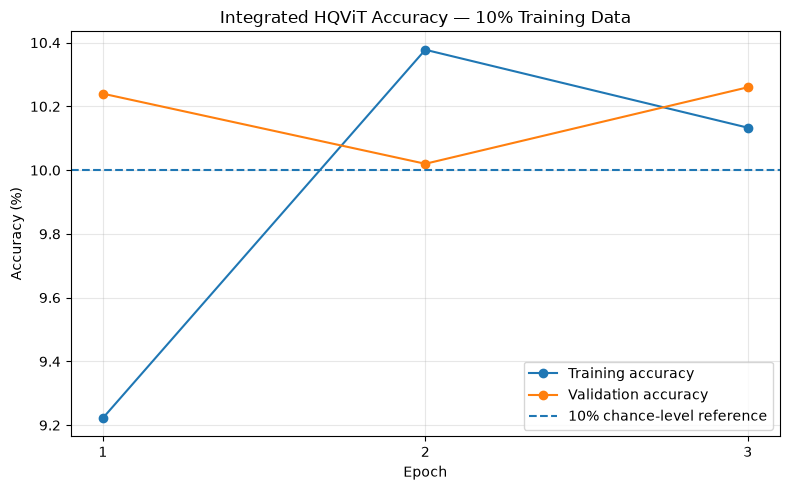

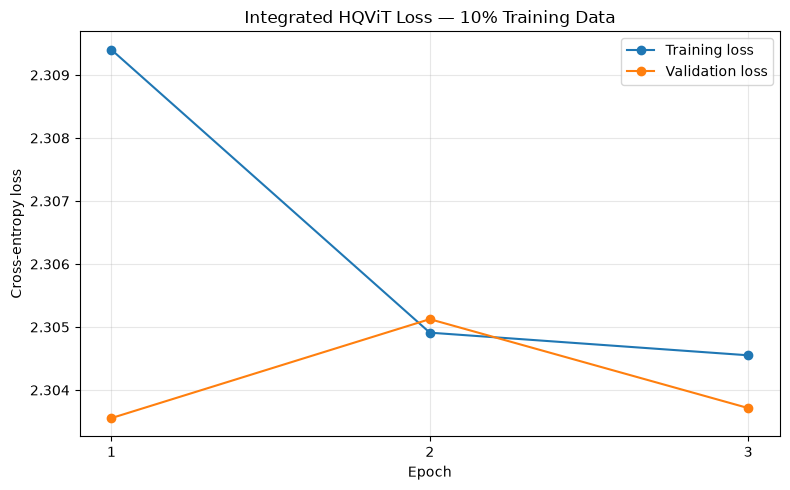

Learning curves saved in results/.


(None,)

In [55]:
import matplotlib.pyplot as plt

epochs = hqvit_history["epoch"]

# Accuracy plot
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    hqvit_history["train_accuracy_pct"],
    marker="o",
    label="Training accuracy",
)

plt.plot(
    epochs,
    hqvit_history["validation_accuracy_pct"],
    marker="o",
    label="Validation accuracy",
)

plt.axhline(
    y=10,
    linestyle="--",
    label="10% chance-level reference",
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Integrated HQViT Accuracy — 10% Training Data")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

os.makedirs("results", exist_ok=True)
plt.savefig(
    "results/hqvit_integrated_accuracy_10pct.png",
    dpi=200,
)
plt.show()


# Loss plot
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    hqvit_history["train_loss"],
    marker="o",
    label="Training loss",
)

plt.plot(
    epochs,
    hqvit_history["validation_loss"],
    marker="o",
    label="Validation loss",
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Integrated HQViT Loss — 10% Training Data")
plt.xticks(epochs)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "results/hqvit_integrated_loss_10pct.png",
    dpi=200,
)
plt.show()

print("Learning curves saved in results/."), 

Section 46: Integrated HQViT Training Diagnostics

The integrated Hybrid Quantum-Classical Vision Transformer achieved 10.13% training accuracy and 10.26% validation accuracy, approximately equal to random guessing for CIFAR-10's ten classes.

This diagnostic examines:

- Training and validation loss trends.
- Changes in model parameters during training.
- Prediction diversity and output-logit variation.
- Quantum feature variation across input images.
- The transformer's final normalization configuration.

These checks will help identify potential implementation or optimization issues before further experiments are conducted.

In [56]:
# Section 46: Integrated HQViT Training Diagnostics

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

print("=" * 70)
print("SECTION 46: INTEGRATED HQViT DIAGNOSTICS")
print("=" * 70)

# ---------------------------------------------------------
# 1. Inspect saved training history
# ---------------------------------------------------------
history_path = "results/hqvit_integrated_history_10pct.csv"

if os.path.exists(history_path):
    history_df = pd.read_csv(history_path)

    print("\n[1] TRAINING HISTORY")
    print(history_df.to_string(index=False))

    if len(history_df) > 1:
        first_loss = float(history_df.iloc[0]["train_loss"])
        last_loss = float(history_df.iloc[-1]["train_loss"])
        print(f"\nTraining-loss change: {first_loss:.4f} -> {last_loss:.4f}")
        print(f"Absolute loss reduction: {first_loss - last_loss:.6f}")
else:
    history_df = None
    print("\n[1] Training-history CSV not found.")

# ---------------------------------------------------------
# 2. Load initial and trained checkpoints
# ---------------------------------------------------------
initial_path = "models/hqvit_integrated_initial.pt"
trained_path = "models/hqvit_integrated_10pct.pt"

print("\n[2] CHECKPOINT COMPARISON")

initial_checkpoint = None
trained_checkpoint = None

if os.path.exists(initial_path):
    initial_checkpoint = torch.load(
        initial_path,
        map_location=DEVICE,
        weights_only=False
    )
    print("Initial checkpoint loaded.")
else:
    print(f"Initial checkpoint missing: {initial_path}")

if os.path.exists(trained_path):
    trained_checkpoint = torch.load(
        trained_path,
        map_location=DEVICE,
        weights_only=False
    )
    print("Trained checkpoint loaded.")
else:
    print(f"Trained checkpoint missing: {trained_path}")

if trained_checkpoint is not None:
    trained_state = trained_checkpoint.get(
        "model_state_dict",
        trained_checkpoint.get("state_dict")
    )

    if trained_state is not None:
        hqvit_model.load_state_dict(trained_state)
        print("Trained weights loaded into hqvit_model.")
    else:
        print("Could not identify the trained state dictionary.")

if initial_checkpoint is not None and trained_checkpoint is not None:
    initial_state = initial_checkpoint.get(
        "model_state_dict",
        initial_checkpoint.get("state_dict")
    )

    if initial_state is not None and trained_state is not None:
        shared_keys = [
            key for key in initial_state
            if key in trained_state
            and isinstance(initial_state[key], torch.Tensor)
            and isinstance(trained_state[key], torch.Tensor)
        ]

        if shared_keys:
            groups = {
                "Transformer": lambda k: k.startswith("vit."),
                "Quantum projection": lambda k: k.startswith("quantum_projection."),
                "Quantum weights": lambda k: k.startswith("quantum_weights"),
                "Classifier": lambda k: k.startswith("classifier.")
            }

            for group_name, selector in groups.items():
                keys = [k for k in shared_keys if selector(k)]

                if not keys:
                    print(f"{group_name}: no matching parameters found.")
                    continue

                squared_change = 0.0
                squared_initial = 0.0

                for key in keys:
                    before = initial_state[key].float()
                    after = trained_state[key].float()

                    squared_change += torch.sum((after - before) ** 2).item()
                    squared_initial += torch.sum(before ** 2).item()

                change_norm = np.sqrt(squared_change)
                initial_norm = np.sqrt(squared_initial)

                print(
                    f"{group_name}: parameter-change norm = "
                    f"{change_norm:.6f}"
                )

                if initial_norm > 0:
                    print(
                        f"    Relative change = "
                        f"{change_norm / initial_norm:.6%}"
                    )

# ---------------------------------------------------------
# 3. Check prediction distribution and output-logit variation
# ---------------------------------------------------------
print("\n[3] PREDICTION DIAGNOSTICS")

hqvit_model.eval()

images, labels = next(iter(validation_loader))
images = images[:64].to(DEVICE)
labels = labels[:64].to(DEVICE)

with torch.no_grad():
    logits = hqvit_model(images)
    probabilities = torch.softmax(logits, dim=1)
    predictions = logits.argmax(dim=1)

prediction_counts = torch.bincount(
    predictions.cpu(),
    minlength=10
)

print("Prediction counts by class:", prediction_counts.tolist())
print("Number of predicted classes:", int((prediction_counts > 0).sum()))
print("Logit mean:", logits.mean().item())
print("Logit standard deviation:", logits.std().item())
print("Mean probability assigned to predicted class:",
      probabilities.max(dim=1).values.mean().item())
print("Accuracy on this diagnostic batch:",
      (predictions == labels).float().mean().item())

# ---------------------------------------------------------
# 4. Inspect quantum feature variability and gradients
# ---------------------------------------------------------
print("\n[4] QUANTUM FEATURE DIAGNOSTICS")

with torch.no_grad():
    tokens = hqvit_model.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    cls_tokens = hqvit_model.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )

    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + hqvit_model.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = hqvit_model.vit.embedding_dropout(tokens)

    # TransformerEncoder applies its configured final norm internally.
    tokens = hqvit_model.vit.transformer(tokens)

    representations = tokens[:, 0, :]
    quantum_inputs = torch.pi * hqvit_model.quantum_projection(
        representations
    )

    print("Transformer representation std:",
          representations.std().item())
    print("Quantum input std:", quantum_inputs.std().item())

    quantum_outputs = []

    # Use a small sample to limit diagnostic runtime.
    for sample in quantum_inputs[:8]:
        result = quantum_circuit(sample, hqvit_model.quantum_weights)

        if isinstance(result, (list, tuple)):
            result = torch.stack([
                value if isinstance(value, torch.Tensor)
                else torch.as_tensor(
                    value, device=sample.device, dtype=sample.dtype
                )
                for value in result
            ])
        elif not isinstance(result, torch.Tensor):
            result = torch.as_tensor(
                result, device=sample.device, dtype=sample.dtype
            )

        quantum_outputs.append(result.reshape(-1))

    quantum_outputs = torch.stack(quantum_outputs)

    print("Quantum output shape:", tuple(quantum_outputs.shape))
    print("Quantum output std:", quantum_outputs.std().item())
    print("Quantum output range:",
          quantum_outputs.min().item(),
          "to",
          quantum_outputs.max().item())

# ---------------------------------------------------------
# 5. Check transformer normalization configuration
# ---------------------------------------------------------
print("\n[5] TRANSFORMER NORMALIZATION")

transformer_norm = getattr(
    hqvit_model.vit.transformer, "norm", None
)

print("Transformer final norm:", transformer_norm)

if transformer_norm is not None:
    print(
        "The TransformerEncoder applies its configured final "
        "normalization internally during forward()."
    )
    print(
        "The integrated model should not apply transformer.norm "
        "a second time after calling transformer(tokens)."
    )

# ---------------------------------------------------------
# 6. Diagnostic summary
# ---------------------------------------------------------
print("\n[6] AUTOMATED FLAGS")

if logits.std().item() < 1e-4:
    print("WARNING: Output logits are nearly constant.")
else:
    print("Output logits show variation across the batch.")

if int((prediction_counts > 0).sum()) <= 2:
    print("WARNING: Predictions cover very few classes.")
else:
    print("Predictions cover multiple classes.")

if quantum_outputs.std().item() < 1e-4:
    print("WARNING: Quantum outputs show very little variation.")
else:
    print("Quantum outputs vary across the sampled images.")

print("\nDiagnostics complete.")
print("No additional training was performed.")

SECTION 46: INTEGRATED HQViT DIAGNOSTICS

[1] TRAINING HISTORY
 epoch  train_loss  train_accuracy  validation_loss  validation_accuracy  epoch_seconds
     1    2.309401        0.092222         2.303555               0.1024     137.107053
     2    2.304911        0.103778         2.305125               0.1002     130.447997
     3    2.304551        0.101333         2.303714               0.1026     129.685986

Training-loss change: 2.3094 -> 2.3046
Absolute loss reduction: 0.004849

[2] CHECKPOINT COMPARISON
Initial checkpoint loaded.
Trained checkpoint loaded.
Trained weights loaded into hqvit_model.
Transformer: parameter-change norm = 13.284547
    Relative change = 25.205754%
Quantum projection: parameter-change norm = 0.345383
    Relative change = 30.890556%
Quantum weights: parameter-change norm = 0.109321
    Relative change = 312.083137%
Classifier: parameter-change norm = 0.650326
    Relative change = 16.672504%

[3] PREDICTION DIAGNOSTICS
Prediction counts by class: [0, 0

Section 47: Correct Transformer Normalization and Verify Gradient Flow

The previous diagnostic identified two issues requiring further investigation: the integrated HQViT predicts a single class for the entire diagnostic batch, and the transformer's final normalization layer is applied twice.

This section corrects the redundant normalization in the model's forward pass. It then verifies that the corrected model produces finite outputs and meaningful gradients through the transformer, quantum projection, quantum circuit parameters, and classifier.

The existing trained checkpoint is retained for reference. This is a diagnostic correction, not evidence that the model has been fixed or that its accuracy will improve.

In [57]:
# Section 47: Correct Transformer Normalization and Verify Gradients

import torch
import torch.nn as nn
import copy

# ---------------------------------------------------------
# 1. Inspect the current HybridQuantumViT forward method
# ---------------------------------------------------------
print("Inspecting the current HybridQuantumViT implementation...")

# Keep a copy of the current trained model for reference.
hqvit_pre_norm_fix = copy.deepcopy(hqvit_model)

# ---------------------------------------------------------
# 2. Define a corrected forward method
# ---------------------------------------------------------
def corrected_hqvit_forward(self, images):
    # Patch embeddings
    tokens = self.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    # Class token and positional embeddings
    cls_tokens = self.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )
    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + self.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = self.vit.embedding_dropout(tokens)

    # TransformerEncoder already applies its configured final norm.
    # Do NOT call self.vit.transformer.norm(tokens) again.
    tokens = self.vit.transformer(tokens)

    # Extract CLS-token representation
    representation = tokens[:, 0, :]

    # Project into quantum circuit input range
    quantum_inputs = torch.pi * self.quantum_projection(representation)

    # Evaluate the quantum circuit for each sample
    quantum_outputs = []

    for sample in quantum_inputs:
        result = quantum_circuit(sample, self.quantum_weights)

        if isinstance(result, (list, tuple)):
            result = torch.stack([
                value if isinstance(value, torch.Tensor)
                else torch.as_tensor(
                    value,
                    device=sample.device,
                    dtype=sample.dtype
                )
                for value in result
            ])
        elif not isinstance(result, torch.Tensor):
            result = torch.as_tensor(
                result,
                device=sample.device,
                dtype=sample.dtype
            )

        quantum_outputs.append(result.reshape(-1))

    quantum_outputs = torch.stack(quantum_outputs, dim=0)
    quantum_outputs = quantum_outputs.to(
        device=images.device,
        dtype=images.dtype
    )

    return self.classifier(quantum_outputs)


# Replace the forward method for this notebook session.
# This does not alter the HybridQuantumViT class definition on disk.
import types

hqvit_model.forward = types.MethodType(
    corrected_hqvit_forward,
    hqvit_model
)

print("Corrected forward method installed for the current model instance.")

# ---------------------------------------------------------
# 3. Run a small forward/backward test
# ---------------------------------------------------------
hqvit_model.train()
hqvit_model.zero_grad(set_to_none=True)

images, labels = next(iter(validation_loader))
images = images[:4].to(DEVICE)
labels = labels[:4].to(DEVICE)

logits = hqvit_model(images)
loss = nn.CrossEntropyLoss()(logits, labels)
loss.backward()

print("\nFORWARD/BACKWARD TEST")
print("Logits shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 6))
print("All logits finite:", bool(torch.isfinite(logits).all()))
print("Loss finite:", bool(torch.isfinite(loss)))

# ---------------------------------------------------------
# 4. Inspect gradient magnitudes
# ---------------------------------------------------------
print("\nGRADIENT DIAGNOSTICS")

parameter_groups = {
    "Transformer": list(hqvit_model.vit.parameters()),
    "Quantum projection": list(hqvit_model.quantum_projection.parameters()),
    "Quantum weights": [hqvit_model.quantum_weights],
    "Classifier": list(hqvit_model.classifier.parameters())
}

for group_name, parameters in parameter_groups.items():
    gradients = [
        parameter.grad.detach()
        for parameter in parameters
        if parameter.grad is not None
    ]

    if not gradients:
        print(f"{group_name}: NO GRADIENTS")
        continue

    all_finite = all(
        bool(torch.isfinite(gradient).all())
        for gradient in gradients
    )

    total_norm = torch.sqrt(
        sum(torch.sum(gradient.float() ** 2) for gradient in gradients)
    ).item()

    print(
        f"{group_name}: gradient norm={total_norm:.8f}, "
        f"finite={all_finite}"
    )

# ---------------------------------------------------------
# 5. Inspect class predictions after the correction
# ---------------------------------------------------------
hqvit_model.eval()

with torch.no_grad():
    logits = hqvit_model(images)
    predictions = logits.argmax(dim=1)
    prediction_counts = torch.bincount(
        predictions.cpu(),
        minlength=10
    )

print("\nPREDICTION CHECK")
print("Predictions:", predictions.cpu().tolist())
print("Class counts:", prediction_counts.tolist())
print("Number of predicted classes:",
      int((prediction_counts > 0).sum()))

print("\nSection 47 complete.")
print("No optimizer step or model training was performed.")

Inspecting the current HybridQuantumViT implementation...
Corrected forward method installed for the current model instance.

FORWARD/BACKWARD TEST
Logits shape: (4, 10)
Loss: 2.336519
All logits finite: True
Loss finite: True

GRADIENT DIAGNOSTICS
Transformer: gradient norm=0.00018850, finite=True
Quantum projection: gradient norm=0.00057364, finite=True
Quantum weights: gradient norm=0.00330000, finite=True
Classifier: gradient norm=0.84557068, finite=True

PREDICTION CHECK
Predictions: [5, 5, 5, 5]
Class counts: [0, 0, 0, 0, 0, 4, 0, 0, 0, 0]
Number of predicted classes: 1

Section 47 complete.
No optimizer step or model training was performed.


Section 48: Investigating Class Collapse and Gradient Imbalance

The integrated HQViT currently predicts a single class despite producing finite logits and gradients. This section investigates whether the observed behaviour is associated with classifier bias, weak gradients in earlier layers, or insufficient variation in the representations supplied to the classification head.

The results will guide the next model modification. No additional training will be performed in this section.

In [58]:
# Section 48: Investigate Class Collapse and Gradient Flow

import torch
import torch.nn as nn
import numpy as np

hqvit_model.eval()

# ---------------------------------------------------------
# 1. Collect a larger validation batch
# ---------------------------------------------------------
images, labels = next(iter(validation_loader))
images = images[:32].to(DEVICE)
labels = labels[:32].to(DEVICE)

with torch.no_grad():
    logits = hqvit_model(images)
    probabilities = torch.softmax(logits, dim=1)
    predictions = logits.argmax(dim=1)

print("=" * 65)
print("SECTION 48: CLASS COLLAPSE INVESTIGATION")
print("=" * 65)

print("\n[1] VALIDATION BATCH")
print("True-label counts:", torch.bincount(
    labels.cpu(), minlength=10
).tolist())

print("Predicted-label counts:", torch.bincount(
    predictions.cpu(), minlength=10
).tolist())

print("Batch accuracy:",
      (predictions == labels).float().mean().item())

print("Mean probability per class:",
      probabilities.mean(dim=0).cpu().numpy().round(4).tolist())

print("Mean maximum probability:",
      probabilities.max(dim=1).values.mean().item())

# ---------------------------------------------------------
# 2. Inspect classifier bias and weight magnitudes
# ---------------------------------------------------------
print("\n[2] CLASSIFIER PARAMETERS")

for name, parameter in hqvit_model.classifier.named_parameters():
    print(
        f"{name}: "
        f"mean={parameter.detach().mean().item():.6f}, "
        f"std={parameter.detach().std().item():.6f}, "
        f"norm={parameter.detach().norm().item():.6f}"
    )

# ---------------------------------------------------------
# 3. Compare gradient norms with parameter norms
# ---------------------------------------------------------
print("\n[3] RELATIVE GRADIENT MAGNITUDES")

hqvit_model.train()
hqvit_model.zero_grad(set_to_none=True)

# Use a small batch to keep the quantum computation manageable.
test_images = images[:4]
test_labels = labels[:4]

test_logits = hqvit_model(test_images)
test_loss = nn.CrossEntropyLoss()(test_logits, test_labels)
test_loss.backward()

groups = {
    "Transformer": list(hqvit_model.vit.parameters()),
    "Quantum projection": list(hqvit_model.quantum_projection.parameters()),
    "Quantum weights": [hqvit_model.quantum_weights],
    "Classifier": list(hqvit_model.classifier.parameters())
}

for group_name, parameters in groups.items():
    grad_sq = 0.0
    param_sq = 0.0
    grad_count = 0

    for parameter in parameters:
        param_sq += parameter.detach().float().pow(2).sum().item()

        if parameter.grad is not None:
            grad_sq += parameter.grad.detach().float().pow(2).sum().item()
            grad_count += 1

    grad_norm = np.sqrt(grad_sq)
    param_norm = np.sqrt(param_sq)
    relative_grad = grad_norm / max(param_norm, 1e-12)

    print(
        f"{group_name}: gradient norm={grad_norm:.8f}, "
        f"parameter norm={param_norm:.6f}, "
        f"relative gradient={relative_grad:.8e}, "
        f"parameters with gradients={grad_count}/{len(parameters)}"
    )

# ---------------------------------------------------------
# 4. Check classifier input diversity
# ---------------------------------------------------------
print("\n[4] QUANTUM FEATURE DIVERSITY")

hqvit_model.eval()

with torch.no_grad():
    tokens = hqvit_model.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    cls_tokens = hqvit_model.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )

    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + hqvit_model.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = hqvit_model.vit.embedding_dropout(tokens)
    tokens = hqvit_model.vit.transformer(tokens)

    representation = tokens[:, 0, :]
    quantum_inputs = torch.pi * hqvit_model.quantum_projection(
        representation
    )

    quantum_outputs = []

    for sample in quantum_inputs:
        result = quantum_circuit(sample, hqvit_model.quantum_weights)

        if isinstance(result, (list, tuple)):
            result = torch.stack([
                value if isinstance(value, torch.Tensor)
                else torch.as_tensor(
                    value, device=sample.device, dtype=sample.dtype
                )
                for value in result
            ])
        elif not isinstance(result, torch.Tensor):
            result = torch.as_tensor(
                result, device=sample.device, dtype=sample.dtype
            )

        quantum_outputs.append(result.reshape(-1))

    quantum_outputs = torch.stack(quantum_outputs)

    print("Transformer representation std:",
          representation.std().item())

    print("Quantum input std:",
          quantum_inputs.std().item())

    print("Quantum features per-dimension std:",
          quantum_outputs.std(dim=0).cpu().numpy().round(5).tolist())

    print("Quantum feature matrix rank:",
          int(torch.linalg.matrix_rank(quantum_outputs).item()))

print("\nSection 48 complete. No optimizer step was performed.")

SECTION 48: CLASS COLLAPSE INVESTIGATION

[1] VALIDATION BATCH
True-label counts: [2, 3, 2, 1, 1, 4, 4, 3, 5, 7]
Predicted-label counts: [0, 0, 0, 0, 0, 32, 0, 0, 0, 0]
Batch accuracy: 0.125
Mean probability per class: [0.10000000149011612, 0.10119999945163727, 0.09730000048875809, 0.10360000282526016, 0.09910000115633011, 0.11089999973773956, 0.10409999638795853, 0.09749999642372131, 0.09120000153779984, 0.09510000050067902]
Mean maximum probability: 0.11088382452726364

[2] CLASSIFIER PARAMETERS
0.weight: mean=-0.005314, std=0.270464, norm=3.048568
0.bias: mean=0.083988, std=0.240505, norm=1.420864
3.weight: mean=-0.012799, std=0.098458, norm=1.773358
3.bias: mean=-0.011463, std=0.100687, norm=0.304230

[3] RELATIVE GRADIENT MAGNITUDES
Transformer: gradient norm=0.00046024, parameter norm=54.185170, relative gradient=8.49375842e-06, parameters with gradients=54/58
Quantum projection: gradient norm=0.00063318, parameter norm=1.175478, relative gradient=5.38658330e-04, parameters with 

Section 49: Quantum Circuit Sensitivity and Expressivity Analysis

The previous diagnostics showed that three of the four quantum expectation-value features have extremely low variation across the validation samples.

This section evaluates the sensitivity of the quantum circuit to its input features and trainable parameters. It examines output variation, input perturbation sensitivity, and the gradients of quantum outputs with respect to the circuit inputs and weights.

The objective is to determine whether the quantum layer is transmitting useful variation from the transformer representation to the classification head. These measurements are diagnostic and do not, by themselves, establish that the circuit is defective.

In [59]:
# Section 49: Quantum Circuit Sensitivity and Expressivity Analysis

import torch
import numpy as np

print("=" * 70)
print("SECTION 49: QUANTUM CIRCUIT SENSITIVITY")
print("=" * 70)

hqvit_model.eval()

# ---------------------------------------------------------
# 1. Obtain transformer representations and quantum inputs
# ---------------------------------------------------------
images, labels = next(iter(validation_loader))
images = images[:16].to(DEVICE)

with torch.no_grad():
    tokens = hqvit_model.vit.patch_embedding(images)
    tokens = tokens.flatten(2).transpose(1, 2)

    cls_tokens = hqvit_model.vit.cls_token.expand(
        tokens.shape[0], -1, -1
    )

    tokens = torch.cat([cls_tokens, tokens], dim=1)
    tokens = tokens + hqvit_model.vit.pos_embedding[:, :tokens.shape[1], :]
    tokens = hqvit_model.vit.embedding_dropout(tokens)
    tokens = hqvit_model.vit.transformer(tokens)

    representations = tokens[:, 0, :]
    quantum_inputs = torch.pi * hqvit_model.quantum_projection(
        representations
    )

print("\n[1] INPUT STATISTICS")
print("Quantum input shape:", tuple(quantum_inputs.shape))
print("Per-dimension input std:",
      quantum_inputs.std(dim=0).cpu().numpy().round(5).tolist())

# ---------------------------------------------------------
# 2. Helper: normalize PennyLane output format
# ---------------------------------------------------------
def evaluate_quantum_output(sample, weights):
    result = quantum_circuit(sample, weights)

    if isinstance(result, (list, tuple)):
        result = torch.stack([
            value if isinstance(value, torch.Tensor)
            else torch.as_tensor(
                value, device=sample.device, dtype=sample.dtype
            )
            for value in result
        ])
    elif not isinstance(result, torch.Tensor):
        result = torch.as_tensor(
            result, device=sample.device, dtype=sample.dtype
        )

    return result.reshape(-1)

# ---------------------------------------------------------
# 3. Check output variation across images
# ---------------------------------------------------------
with torch.no_grad():
    quantum_outputs = torch.stack([
        evaluate_quantum_output(
            sample, hqvit_model.quantum_weights
        )
        for sample in quantum_inputs
    ])

print("\n[2] QUANTUM OUTPUT VARIATION")
print("Per-qubit output means:",
      quantum_outputs.mean(dim=0).cpu().numpy().round(5).tolist())
print("Per-qubit output std:",
      quantum_outputs.std(dim=0).cpu().numpy().round(7).tolist())
print("Per-qubit output ranges:")

for qubit_index in range(quantum_outputs.shape[1]):
    values = quantum_outputs[:, qubit_index]
    print(
        f"  Qubit {qubit_index + 1}: "
        f"min={values.min().item():.6f}, "
        f"max={values.max().item():.6f}"
    )

# ---------------------------------------------------------
# 4. Test sensitivity to each input dimension
# ---------------------------------------------------------
print("\n[3] INPUT PERTURBATION SENSITIVITY")

base_input = quantum_inputs[0].detach()
weights = hqvit_model.quantum_weights.detach()

with torch.no_grad():
    base_output = evaluate_quantum_output(base_input, weights)

    epsilon = 0.1

    for dimension in range(base_input.numel()):
        perturbed_input = base_input.clone()
        perturbed_input[dimension] += epsilon

        perturbed_output = evaluate_quantum_output(
            perturbed_input, weights
        )

        output_change = torch.norm(
            perturbed_output - base_output
        ).item()

        print(
            f"Input dimension {dimension + 1}: "
            f"output change after +{epsilon} perturbation = "
            f"{output_change:.8f}"
        )

# ---------------------------------------------------------
# 5. Compute gradients of quantum outputs
# ---------------------------------------------------------
print("\n[4] QUANTUM INPUT AND WEIGHT GRADIENTS")

sample = quantum_inputs[0].detach().clone().requires_grad_(True)
weights_for_grad = (
    hqvit_model.quantum_weights.detach().clone().requires_grad_(True)
)

output = evaluate_quantum_output(sample, weights_for_grad)

for output_index in range(output.numel()):
    input_grad, weight_grad = torch.autograd.grad(
        output[output_index],
        (sample, weights_for_grad),
        retain_graph=(output_index < output.numel() - 1),
        allow_unused=True
    )

    input_grad_norm = (
        input_grad.norm().item()
        if input_grad is not None else None
    )

    weight_grad_norm = (
        weight_grad.norm().item()
        if weight_grad is not None else None
    )

    print(
        f"Output {output_index + 1}: "
        f"input-gradient norm={input_grad_norm}, "
        f"weight-gradient norm={weight_grad_norm}"
    )

print("\nSection 49 complete. No training or optimizer update performed.")

SECTION 49: QUANTUM CIRCUIT SENSITIVITY

[1] INPUT STATISTICS
Quantum input shape: (16, 4)
Per-dimension input std: [0.00011000000085914508, 0.002570000011473894, 0.013129999861121178, 0.0004199999966658652]

[2] QUANTUM OUTPUT VARIATION
Per-qubit output means: [-0.99914, -0.99776, 0.99639, 0.99737]
Per-qubit output std: [4.5e-06, 7.91e-05, 0.0007628, 7.08e-05]
Per-qubit output ranges:
  Qubit 1: min=-0.999150, max=-0.999134
  Qubit 2: min=-0.997988, max=-0.997647
  Qubit 3: min=0.993608, max=0.996744
  Qubit 4: min=0.997265, max=0.997562

[3] INPUT PERTURBATION SENSITIVITY
Input dimension 1: output change after +0.1 perturbation = 0.01289394
Input dimension 2: output change after +0.1 perturbation = 0.00349172
Input dimension 3: output change after +0.1 perturbation = 0.00128114
Input dimension 4: output change after +0.1 perturbation = 0.00235956

[4] QUANTUM INPUT AND WEIGHT GRADIENTS
Output 1: input-gradient norm=0.04144606739282608, weight-gradient norm=0.04145454987883568
Output 